<table>
    <tr>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="300"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Machine Learning  </p> Algoritmos</p> Trabajo Final </FONT>         </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Aprendizaje Automático de Máquina </p></tp>
            <tp><p style="font-size:115%;text-align:center">Pregrado MACC 2026-1</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
            <tp><p style="font-size:115%;text-align:center">Est. Sebastián Sánchez y Sofía Torres</p></tp>
        </td>
    </tr>
</table>

# <FONT SIZE=5 COLOR="purple"> **Indicaciones** </FONT>

Antes de iniciar el taller lea detenidamente las instrucciones:

- Para entregar en grupos de dos o tres personas.

- **Importante:** Cargar en la plataforma *e-aulas* los archivos: ***.ipynb*** y ***.pdf***.

- Realizar cada punto en un **notebook y pdf diferente** siguiendo el siguiente esquema para nombrarlos

$$ML\_2026\_1\_final\_Punto\_1(fabian-hugo-carlos)$$

- Anexe el link o el conjunto de datos que utilizó para cada punto.

- Fecha máxima de entrega:  **martes 26 de mayo las 6:00 p.m.** y sustentación el **miércoles 27 de mayo, en clase**

- El porcentaje del trabajo es el $60\%$ y el porcentaje de la sustentación $40\%$.

- **Observaciones para la sustentación**: el día viernes 22 de mayo se cargarán a e-aulas 15 preguntas conceptuales. El día de la sustentación el grupo seleccionará dos preguntas al azar para que dos estudiantes del grupo las respondan (las respuestas serán evaluadas con 0; 3.0 ; 5.0 cada una).



Páginas recomendadas para buscar datos

- Kaggle

- Github. Awesome Public Datasets (GitHub)

- UCI Machine Learning Repository

- Datos.gov

- Google Dataset Search

- Hugging Face Datasets

- https://data.worldbank.org/

# <FONT SIZE=5 COLOR="purple"> **Librerias** </FONT>

In [ ]:
# Sistema y descarga de datos
import os
import kagglehub

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y modelado
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

# Modelos (Algoritmos de aprendizaje)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

# <FONT SIZE=5 COLOR="purple"> **1. Clasificación** </FONT>

- Buscar un conjunto de datos (>2000 registros) al cuál se le pueda aplicar algoritmos de clasificación. Es decir, que busque predecir una variable con dos o más categorias.

- Explorar los datos

- Aplicar modelos: regresión logística, árboles de decisión y Random Forest

- Evaluar los modelos y seleccionar el mejor con la curva ROC.

- Hacer algunas predicciones.



## <FONT SIZE=5 COLOR="purple"> **1.1 Descripción del problema** </FONT>

Este proyecto aborda un problema de clasificación automática de correos electrónicos, específicamente la detección de correos spam (maliciosos o no deseados) frente a correos legítimos (no spam). En la actualidad, el volumen de correos electrónicos es extremadamente alto y una parte significativa corresponde a mensajes fraudulentos, publicitarios o potencialmente peligrosos. Por esta razón, es fundamental desarrollar modelos capaces de identificar patrones que permitan filtrar este tipo de contenido de forma automática.

El objetivo principal del proyecto es construir modelos de Machine Learning que, a partir de características estructurales, textuales y temporales de los correos, puedan predecir si un mensaje pertenece a la clase spam (1) o no spam (0).

Los datos fuero tomados de Kaggle:
https://www.kaggle.com/datasets/ssssws/spam-email-detection-dataset-clean-and-ml-ready


***Variable objetivo***

La variable objetivo del modelo es:

`label` : indica la clase del correo electrónico

0 → correo legítimo (no spam)
1 → correo spam

Esta variable es la que los modelos intentan predecir a partir del resto de características del dataset.

Las variables explicativas describen diferentes aspectos del contenido, el comportamiento del remitente y la estructura del correo:


***Identificación y contenido***
- `email_id`: identificador único de cada correo, usado solo para referencia.
- `subject`: asunto del correo electrónico, el cual puede contener patrones de spam como promociones o urgencia.
- `email_text`: contenido completo del mensaje. Suele ser una de las fuentes más importantes de información, aunque puede requerir procesamiento de texto.

***Características del texto***
- `num_words`: número total de palabras del correo.
- `num_characters`: longitud del mensaje en caracteres.
- `num_exclamation_marks`: cantidad de signos de exclamación, frecuentemente asociados a mensajes llamativos o spam.

***Enlaces y archivos***
- `num_links`: número de enlaces incluidos en el correo.
- `has_suspicious_link`: indica si el correo contiene enlaces potencialmente peligrosos.
- `num_attachments`: número de archivos adjuntos.
- `has_attachment`: indica si el correo contiene o no adjuntos.

***Información del remitente***
- `sender_email`: dirección de correo del remitente.
- `sender_domain`: dominio del correo (ej. gmail.com, yahoo.com), útil para detectar dominios sospechosos.
- `sender_reputation_score`: puntaje que mide la confiabilidad del remitente.

***Información temporal***
- `email_hour`: hora en la que se envió el correo.
- `email_day_of_week`: día de la semana del envío.
- `is_weekend`: indica si el correo fue enviado en fin de semana.

***Distribución del mensaje***
- `num_recipients`: número de destinatarios del correo.

***Lenguaje del mensaje***
- `contains_money_terms`: indica si el correo contiene términos relacionados con dinero, premios u ofertas.
- `contains_urgency_terms`: indica si el correo usa lenguaje de urgencia o presión (ej. “¡URGENTE!”, “última oportunidad”).


## <FONT SIZE=5 COLOR="purple"> **1.2 Exploración de datos** </FONT>

### <FONT SIZE=5 COLOR="purple"> **1.2.1 Carga y exploración inicial de datos** </FONT>

Realizamos la carga de datos desde Kaggle

In [ ]:
import kagglehub
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Download latest version
path = kagglehub.dataset_download("ssssws/spam-email-detection-dataset-clean-and-ml-ready")

print("Path to dataset files:", path)
email = pd.read_csv(path + "/" + os.listdir(path)[0])

Using Colab cache for faster access to the 'spam-email-detection-dataset-clean-and-ml-ready' dataset.
Path to dataset files: /kaggle/input/spam-email-detection-dataset-clean-and-ml-ready


In [ ]:
email.shape

(10000, 20)

El dataset de detección de emails fradulentos cuenta con 10000 observaciones y 20 variable

In [ ]:
# Mostrar información básica
print("\nPrimeras filas:")
print(email.head())


Primeras filas:
   email_id           subject  \
0         0     Weekly Report   
1         1    Project Update   
2         2    🔥WIN BIG NOW!!   
3         3    🔥WIN BIG NOW!!   
4         4  Meeting Reminder   

                                          email_text  num_words  \
0  budget review - Statement our I claim world st...         19   
1  team sync - President series today already. In...         18   
2  win free urgent offer limited limited urgent u...         19   
3  guarantee click now cash offer click now guara...         16   
4  team sync - Significant property hotel not add...         18   

   num_characters  num_exclamation_marks  num_links  has_suspicious_link  \
0             114                      0          2                    0   
1             114                      0          7                    0   
2             126                      0          4                    1   
3             101                      0          7                    1   
4

El dataset cuenta con variables relacionadas con las características de correos electrónicos, incluyendo información textual, métricas del contenido y características del remitente. Entre las variables disponibles se encuentran:

* `email_id`: identificador único del correo.
* `subject`: asunto del correo electrónico.
* `email_text`: contenido del correo.
* `num_words`: número de palabras del mensaje.
* `num_characters`: número de caracteres.
* `num_exclamation_marks`: cantidad de signos de exclamación.
* `num_links`: número de enlaces presentes en el correo.
* `has_suspicious_link`: indicador de enlaces sospechosos.
* `num_attachments`: cantidad de archivos adjuntos.
* `has_attachment`: indicador de presencia de adjuntos.
* `sender_email`: dirección de correo del remitente.
* `sender_domain`: dominio del remitente.
* `sender_reputation_score`: puntaje de reputación del remitente.
* `email_hour`: hora de envío del correo.
* `email_day_of_week`: día de la semana del envío.
* `is_weekend`: indicador de fin de semana.
* `num_recipients`: número de destinatarios.
* `contains_money_terms`: presencia de términos relacionados con dinero.
* `contains_urgency_terms`: presencia de términos de urgencia.
* `label`: variable objetivo que clasifica el correo como spam (`1`) o no spam (`0`).

Estas variables permiten realizar análisis exploratorio de datos y construir modelos de clasificación para detección de spam.


In [ ]:
email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   email_id                 10000 non-null  int64  
 1   subject                  10000 non-null  object 
 2   email_text               10000 non-null  object 
 3   num_words                10000 non-null  int64  
 4   num_characters           10000 non-null  int64  
 5   num_exclamation_marks    10000 non-null  int64  
 6   num_links                10000 non-null  int64  
 7   has_suspicious_link      10000 non-null  int64  
 8   num_attachments          10000 non-null  int64  
 9   has_attachment           10000 non-null  int64  
 10  sender_email             10000 non-null  object 
 11  sender_domain            10000 non-null  object 
 12  sender_reputation_score  10000 non-null  float64
 13  email_hour               10000 non-null  int64  
 14  email_day_of_week      

El dataset corresponde a un DataFrame de pandas con un total de 10 000 registros y 20 variables. Todas las columnas cuentan con 10 000 valores no nulos, por lo que no se presentan datos faltantes.
Respecto a los tipos de datos presentes:

Variables de tipo int64: `email_id`, `num_words`, `num_characters`, `num_exclamation_marks` `num_links`, `has_suspicious_link`, `num_attachments`, `has_attachment`, `email_hour`, `email_day_of_week`, `is_weekend`, `num_recipients`, `contains_money_terms`, `contains_urgency_terms`, `label`

Variables de tipo float64:`sender_reputation_score`

Variables de tipo object:`subject`, `email_text`, `sender_email`, `sender_domain`

En un primer análisis tenemos estos tipos de variables, sin embargo el dataset tiene variables booleanas que estan codificadas con 1 y 0.

Revisamos las variables que se creen booleanas: `has_suspicious_link`, `has_attachment`, `is_weekend`, `contains_money_terms`, `contains_urgency_terms` y `label` :



In [ ]:
variables_booleanas = [
    'has_suspicious_link',
    'has_attachment',
    'is_weekend',
    'contains_money_terms',
    'contains_urgency_terms',
    'label'
]

for col in variables_booleanas:
    print(f"\nValores únicos de {col}:")
    print(email[col].unique())


Valores únicos de has_suspicious_link:
[0 1]

Valores únicos de has_attachment:
[1 0]

Valores únicos de is_weekend:
[0 1]

Valores únicos de contains_money_terms:
[0 1]

Valores únicos de contains_urgency_terms:
[0 1]

Valores únicos de label:
[0 1]


Las variables `has_suspicious_link`, `has_attachment`, `is_weekend`, `contains_money_terms`, `contains_urgency_terms` y `label` tienen valores únicos de 0 y 1, por tanto son booleanas.

Ahora realizamos un análisis descriptivo de las variables numéricas.

In [ ]:
columnas = [
    'num_words',
    'num_characters',
    'num_exclamation_marks',
    'num_links',
    'num_attachments',
    'sender_reputation_score',
    'email_hour',
    'email_day_of_week',
    'num_recipients'
]

email[columnas].describe()

,num_words,num_characters,num_exclamation_marks,num_links,num_attachments,sender_reputation_score,email_hour,email_day_of_week,num_recipients
count,10000.000000,10000.000000,10000.0,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,18.097000,115.072400,0.0,3.976400,0.803600,0.681972,11.589600,3.00580,15.501100
std,5.163764,33.781247,0.0,2.580447,0.752252,0.172825,6.897023,2.00309,8.650577
min,5.000000,25.000000,0.0,0.000000,0.000000,0.300000,0.000000,0.00000,1.000000
25%,14.000000,91.000000,0.0,2.000000,0.000000,0.560000,6.000000,1.00000,8.000000
50%,18.000000,115.500000,0.0,4.000000,1.000000,0.690000,12.000000,3.00000,16.000000
75%,22.000000,139.000000,0.0,6.000000,1.000000,0.810000,18.000000,5.00000,23.000000
max,33.000000,221.000000,0.0,8.000000,2.000000,1.000000,23.000000,6.00000,30.000000


La tabla presenta estadísticas descriptivas de las principales variables numéricas del dataset de correos electrónicos. En general, se observa que los mensajes tienen una longitud moderada y que varias características muestran una dispersión relativamente controlada.

La variable `num_words` indica que los correos contienen en promedio aproximadamente 18 palabras, con valores entre 5 y 33 palabras. La desviación estándar de 5.16 sugiere una variabilidad moderada en la longitud de los mensajes.

De forma similar, `num_characters` presenta un promedio de 115 caracteres y un rango entre 25 y 221 caracteres, lo que muestra diferencias considerables en el tamaño de los correos electrónicos.

La variable `num_exclamation_marks` tiene valor 0 en todos los registros, por lo que no aporta variabilidad ni información relevante para el análisis o entrenamiento de modelos.

Respecto a los enlaces, `num_links` tiene un promedio cercano a 4 enlaces por correo, con valores entre 0 y 8. Esto podría ser una característica importante para diferenciar correos spam de no spam, ya que mensajes fraudulentos suelen contener múltiples enlaces.

En `num_attachments` se observa que la mayoría de los correos tienen entre 0 y 1 archivo adjunto, aunque algunos alcanzan hasta 2 adjuntos.

La variable `sender_reputation_score` muestra un promedio de 0.68 en una escala de 0.3 a 1.0, indicando que la mayoría de los remitentes poseen reputaciones relativamente buenas. Sin embargo, existen remitentes con reputaciones bajas que podrían estar asociados a spam.

En cuanto al tiempo de envío, `email_hour` presenta una distribución amplia entre las 0 y las 23 horas, con una mediana cercana al mediodía. Esto indica que los correos fueron generados en diferentes momentos del día.

La variable `email_day_of_week` cubre todos los días de la semana, con una mediana de 3, sugiriendo una distribución relativamente uniforme entre días laborales y fines de semana.

Finalmente, `num_recipients` tiene un promedio de aproximadamente 15 destinatarios por correo y valores entre 1 y 30 destinatarios. La desviación estándar relativamente alta indica una variabilidad considerable en la cantidad de receptores, característica que también podría ser útil para identificar comportamientos asociados a spam masivo.

En conjunto, las variables presentan suficiente variabilidad y características potencialmente relevantes para tareas de análisis exploratorio y clasificación de correos electrónicos spam.


Tras la revisión inicial del dataset, se decidió eliminar las variables `email_id`, `email_text` y `num_exclamation_marks`. Las dos primeras no aportan información relevante para los modelos de clasificación, ya que contienen valores mayoritariamente únicos para cada observación. Por otro lado, la variable `num_exclamation_marks` fue eliminada debido a que todos sus registros presentan el mismo valor (`0`), por lo que no aporta variabilidad ni capacidad predictiva al modelo.


In [ ]:
# Eliminar columnas permanentemente
email.drop(
    columns=[
        'email_id',
        'email_text',
        'num_exclamation_marks'
    ],
    inplace=True
)

# Verificar columnas restantes
print(email.columns)

Index(['subject', 'num_words', 'num_characters', 'num_links',
       'has_suspicious_link', 'num_attachments', 'has_attachment',
       'sender_email', 'sender_domain', 'sender_reputation_score',
       'email_hour', 'email_day_of_week', 'is_weekend', 'num_recipients',
       'contains_money_terms', 'contains_urgency_terms', 'label'],
      dtype='object')


### <FONT SIZE=5 COLOR="purple"> **1.2.2 Exploración de variable por variable** </FONT>

Ahora realizaremos un análisis de variable por variable

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.1 Exploración de variable subject** </FONT>

Se realiza la exploración de la variable `subject`

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


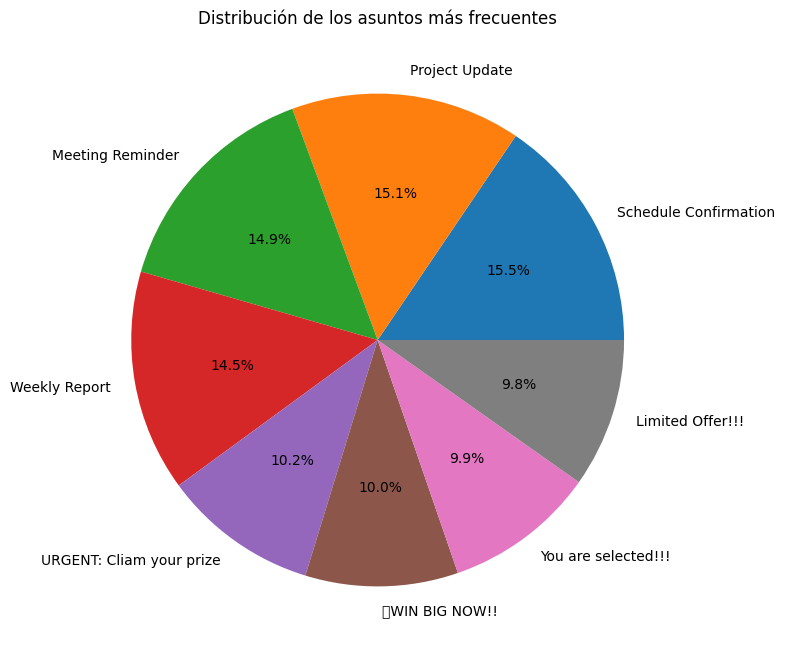

In [ ]:
top_subjects = email['subject'].value_counts().head(10)

plt.figure(figsize=(8,8))
plt.pie(
    top_subjects,
    labels=top_subjects.index,
    autopct='%1.1f%%'
)

plt.title('Distribución de los asuntos más frecuentes')
plt.show()

La distribución de la variable `subject` muestra que los asuntos de los correos electrónicos se encuentran relativamente balanceados entre categorías relacionadas con mensajes legítimos y posibles correos spam.

Los asuntos más frecuentes corresponden a mensajes comunes de tipo corporativo o informativo, como `Schedule Confirmation` (15.5 %), `Project Update` (15.1 %), `Meeting Reminder` (14.9 %) y `Weekly Report` (14.5 %). En conjunto, estas categorías representan aproximadamente el 60 % del total de correos analizados, lo que indica una alta presencia de mensajes considerados normales o de carácter laboral.

Por otro lado, también se observan asuntos asociados a posibles correos spam o fraudulentos, como `URGENT: Cliam your prize` (10.2 %), `🔥WIN BIG NOW!!` (10.0 %), `You are selected!!!` (9.9 %) y `Limited Offer!!!` (9.8%). Estos asuntos suelen incluir palabras relacionadas con urgencia, premios, promociones o incentivos, características comúnmente asociadas a campañas de spam.

En general, la variable `subject` parece tener una alta capacidad informativa para tareas de clasificación, ya que existe una diferencia clara entre los patrones de asuntos legítimos y aquellos potencialmente fraudulentos. Esto sugiere que el asunto del correo podría ser una característica relevante para modelos de detección de spam.


#### <FONT SIZE=5 COLOR="purple"> **1.2.2.2 Exploración de variable num_words** </FONT>

Se realiza la exploración de la variable `num_words`

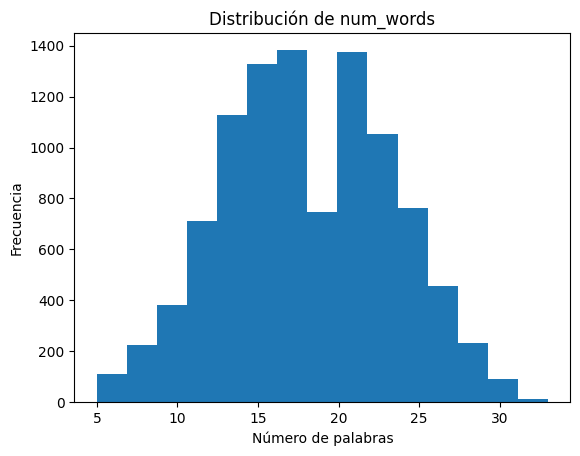

In [ ]:
plt.hist(email['num_words'], bins=15)
plt.xlabel('Número de palabras')
plt.ylabel('Frecuencia')
plt.title('Distribución de num_words')
plt.show()

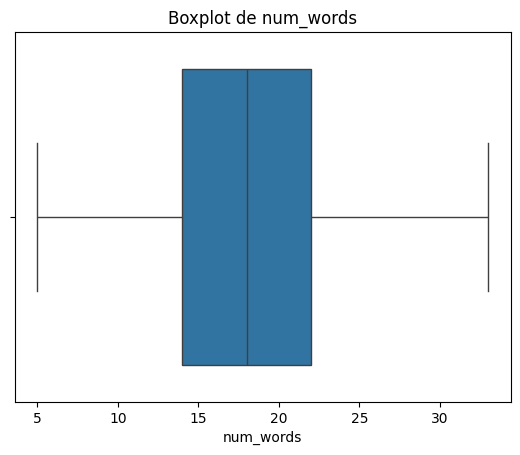

In [ ]:
sns.boxplot(x=email['num_words'])
plt.title('Boxplot de num_words')
plt.show()

La gráfica muestra la distribución de la variable num_words, correspondiente al número de palabras presentes en cada correo electrónico. Se observa una distribución aproximadamente simétrica y con forma cercana a una campana, concentrándose la mayor cantidad de observaciones entre 14 y 24 palabras.

La frecuencia máxima se encuentra alrededor de los valores entre 16 y 22 palabras, lo que indica que la mayoría de los correos poseen una longitud moderada y relativamente homogénea.

Además, se aprecia una menor cantidad de correos con muy pocas palabras (cerca de 5 a 10) o con cantidades altas de palabras (mayores a 28), por lo que los valores extremos son poco frecuentes dentro del dataset.

La distribución no presenta sesgos pronunciados y el boxplot nos muestra que no hay datos atípicos, lo que sugiere que la variable tiene un comportamiento estable y adecuado para ser utilizada en modelos de machine learning.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.3 Exploración de variable num_characters** </FONT>

Se realiza la exploración de la variable `num_characters`

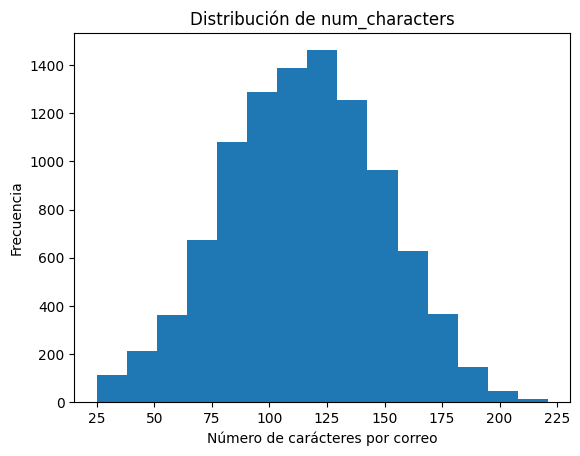

In [ ]:
plt.hist(email['num_characters'], bins=15)
plt.xlabel('Número de carácteres por correo')
plt.ylabel('Frecuencia')
plt.title('Distribución de num_characters')
plt.show()

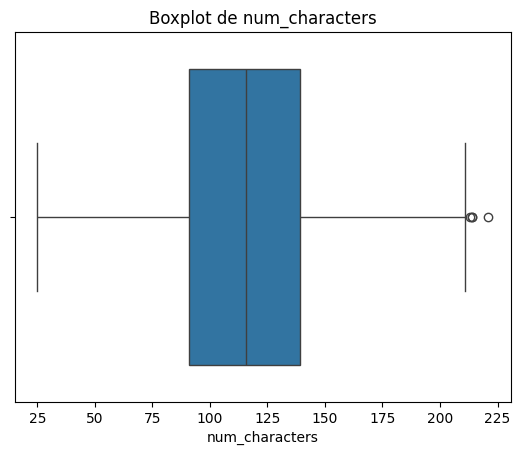

In [ ]:
sns.boxplot(x=email['num_characters'])
plt.title('Boxplot de num_characters')
plt.show()

La variable `num_characters` presenta una distribución aproximadamente normal, evidenciada por una forma similar a una campana. Se observa que la mayor concentración de datos se encuentra en los valores centrales, aproximadamente entre 68 y 168 caracteres, mientras que en los extremos aparecen menos observaciones.

Además, la mayoría de los correos electrónicos contienen entre 118 y 128 caracteres, lo que indica una longitud relativamente homogénea en los mensajes del dataset.

Por otro lado, el boxplot muestra la presencia de pocos valores atípicos, sugiriendo que la variable no presenta una cantidad significativa de observaciones extremas y mantiene un comportamiento estable para el análisis y modelado.


#### <FONT SIZE=5 COLOR="purple"> **1.2.2.4 Exploración de variable num_links** </FONT>

Se realiza la exploración de la variable `num_links`

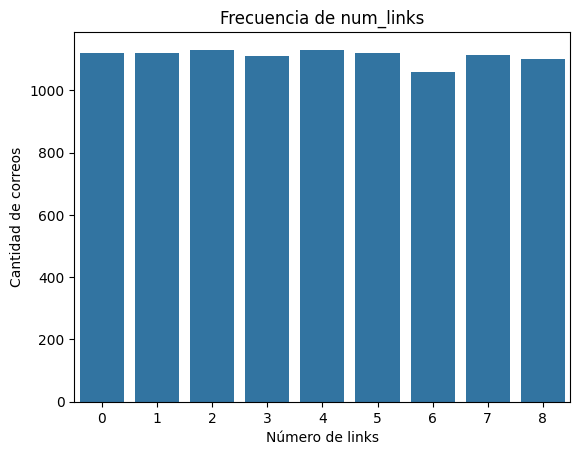

In [ ]:
sns.countplot(x='num_links', data=email)

plt.xlabel('Número de links')
plt.ylabel('Cantidad de correos')
plt.title('Frecuencia de num_links')

plt.show()

La distribución de la variable `num_links` muestra que la cantidad de enlaces presentes en los correos electrónicos toma valores entre 0 y 8 links. A partir de la gráfica, se observa que las frecuencias para cada cantidad de enlaces son relativamente similares, lo que indica una distribución aproximadamente uniforme.

Además, cada categoría de número de enlaces presenta entre 1000 y 1200 observaciones aproximadamente, por lo que no existe una concentración excesiva de datos en un valor específico. Esto sugiere que el dataset contiene una representación equilibrada de correos con diferentes cantidades de enlaces.

La uniformidad observada en la distribución puede resultar beneficiosa para el entrenamiento de modelos de machine learning, ya que evita sesgos hacia una cantidad particular de enlaces y permite analizar de manera más adecuada la relación entre el número de links y la clasificación de correos spam o no spam.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.5 Exploración de variable has_suspicious_link** </FONT>

Se realiza la exploración de la variable `has_suspicious_link`

In [ ]:
print(email['has_suspicious_link'].value_counts())

has_suspicious_link
0    5333
1    4667
Name: count, dtype: int64


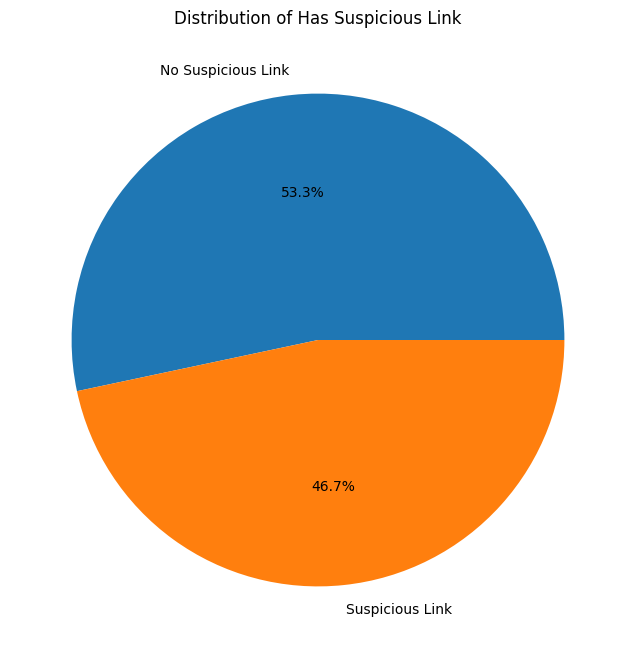

In [ ]:
suspicious_link_counts = email['has_suspicious_link'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    suspicious_link_counts,
    labels=['No Suspicious Link', 'Suspicious Link'],
    autopct='%1.1f%%'
)

plt.title('Distribution of Has Suspicious Link')
plt.show()

La variable `has_suspicious_link` muestra que el 53.3 % de los correos electrónicos no contiene enlaces sospechosos, mientras que el 46.7 % restante sí presenta este tipo de enlaces.

Estos resultados indican que existe una distribución relativamente equilibrada entre correos con y sin links sospechosos dentro del dataset. Además, la presencia de enlaces sospechosos puede representar una característica importante para la detección de spam, ya que este tipo de correos suele incluir enlaces fraudulentos o potencialmente peligrosos para el usuario.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.6 Exploración de variable num_attachments** </FONT>

Se realiza la exploración de la variable `num_attachments`

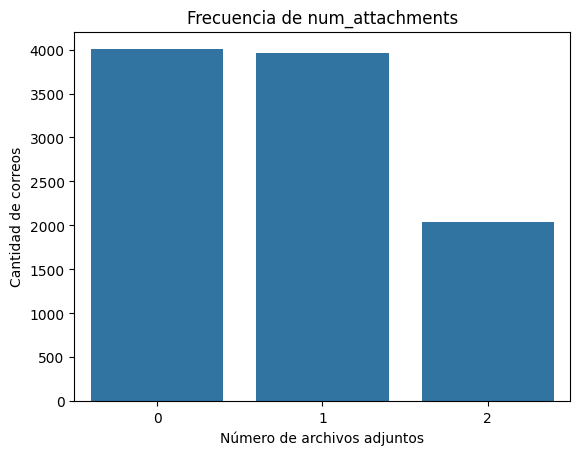

In [ ]:
sns.countplot(x='num_attachments', data=email)

plt.xlabel('Número de archivos adjuntos')
plt.ylabel('Cantidad de correos')
plt.title('Frecuencia de num_attachments')

plt.show()

La variable `num_attachments` representa la cantidad de archivos adjuntos presentes en cada correo electrónico. A partir del análisis de la distribución, se observa que aproximadamente 4000 correos contienen entre 0 y 1 archivo adjunto, lo que indica que la mayoría de los mensajes poseen pocos o ningún documento adicional.
Por otro lado, cerca de 2000 correos electrónicos presentan 2 archivos adjuntos, siendo este el valor máximo registrado para la variable.

En general, la distribución muestra una mayor concentración de observaciones en cantidades bajas de adjuntos, lo cual es coherente con el comportamiento habitual de los correos electrónicos. Además, esta variable podría resultar relevante para la detección de spam, ya que ciertos correos fraudulentos suelen incluir archivos adjuntos como medio para distribuir contenido malicioso o captar la atención del usuario.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.7 Exploración de variable has_attachment** </FONT>

Se realiza la exploración de la variable `has_attachment`

In [ ]:
print(email['has_attachment'].value_counts())

has_attachment
1    5996
0    4004
Name: count, dtype: int64


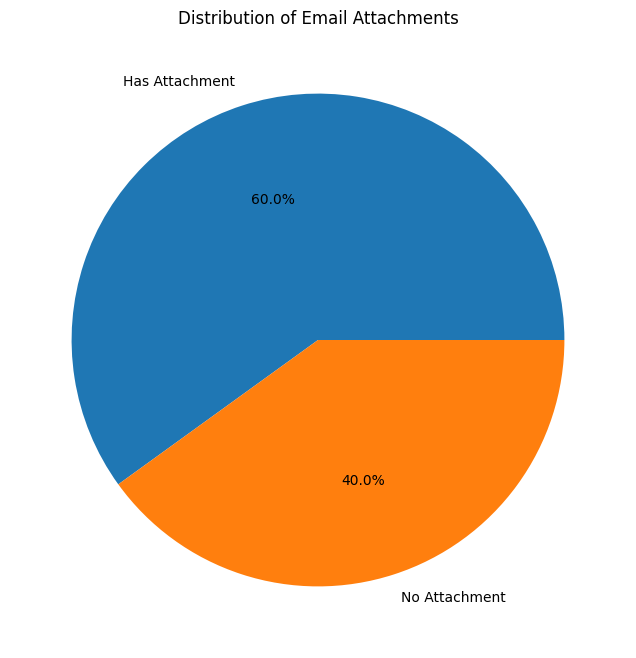

In [ ]:
attachment_counts = email['has_attachment'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    attachment_counts,
    labels=['Has Attachment','No Attachment'],
    autopct='%1.1f%%'
)

plt.title('Distribution of Email Attachments')
plt.show()

La distribución de la variable `has_attachment` muestra que aproximadamente el 60 % de los correos electrónicos contienen al menos un archivo adjunto, mientras que el 40 % restante no presenta adjuntos. Esto indica que la presencia de archivos adjuntos es una característica frecuente dentro del dataset y podría aportar información relevante para la clasificación de correos electrónicos.

In [ ]:
pd.crosstab(
    email['num_attachments'],
    email['has_attachment']
)

has_attachment,0,1
num_attachments,,
0,4004,0
1,0,3956
2,0,2040


Posteriormente, se realizó una tabla cruzada entre las variables `has_attachment` y `num_attachments` con el fin de analizar su relación. A partir de este análisis se observó que ambas variables contienen información redundante, ya que `has_attachment` depende directamente del número de adjuntos presentes en el correo. Es decir, cuando `num_attachments` es igual a 0, `has_attachment` toma el valor 0, mientras que para valores mayores a 0, `has_attachment` toma el valor 1. Debido a esta relación directa, se decidió eliminar la variable `has_attachment` y conservar únicamente `num_attachments`, ya que proporciona un mayor nivel de detalle.

In [ ]:
# Eliminar la variable has_attachment
email.drop(columns=['has_attachment'], inplace=True)

# Verificar columnas restantes
print(email.columns)

Index(['subject', 'num_words', 'num_characters', 'num_links',
       'has_suspicious_link', 'num_attachments', 'sender_email',
       'sender_domain', 'sender_reputation_score', 'email_hour',
       'email_day_of_week', 'is_weekend', 'num_recipients',
       'contains_money_terms', 'contains_urgency_terms', 'label'],
      dtype='object')


#### <FONT SIZE=5 COLOR="purple"> **1.2.2.8 Exploración de variable sender_email** </FONT>

Se realiza la exploración de la variable `sender_email`

In [ ]:
# Tabla de valores únicos de sender_email
tabla_sender_email = email['sender_email'].value_counts().reset_index()

# Renombrar columnas
tabla_sender_email.columns = ['sender_email', 'frecuencia']

# Mostrar tabla
tabla_sender_email

,sender_email,frecuencia
0,uvmcadi@freemoney.biz,1
1,lyigvaa@chealdealz.xyz,1
2,pjtqheb@freemoney.biz,1
3,ocwbuur@gmail.com,1
4,yjauaem@chealdealz.xyz,1
...,...,...
9995,xoiccxl@yahoo.com,1
9996,qalxcnf@chealdealz.xyz,1
9997,atvanls@unknownmail.cc,1
9998,pxyldmi@company.com,1


In [ ]:
# Eliminar la variable sender_email
email.drop(columns=['sender_email'], inplace=True)

# Verificar columnas restantes
print(email.columns)

Index(['subject', 'num_words', 'num_characters', 'num_links',
       'has_suspicious_link', 'num_attachments', 'sender_domain',
       'sender_reputation_score', 'email_hour', 'email_day_of_week',
       'is_weekend', 'num_recipients', 'contains_money_terms',
       'contains_urgency_terms', 'label'],
      dtype='object')


Tras analizar la variable `sender_email`, se observó que las direcciones de correo de los remitentes son diferentes para prácticamente todas las observaciones del dataset. Esto implica que la variable presenta una alta cardinalidad y no aporta patrones relevantes para el proceso de clasificación.

Debido a que cada correo electrónico posee un identificador de remitente prácticamente único, la variable no contribuye significativamente al entrenamiento de modelos de machine learning y podría introducir ruido innecesario en el análisis. Por esta razón, se decidió eliminar la variable `sender_email` del dataset.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.9 Exploración de variable sender_domain** </FONT>

Se realiza la exploración de la variable `sender_domain`

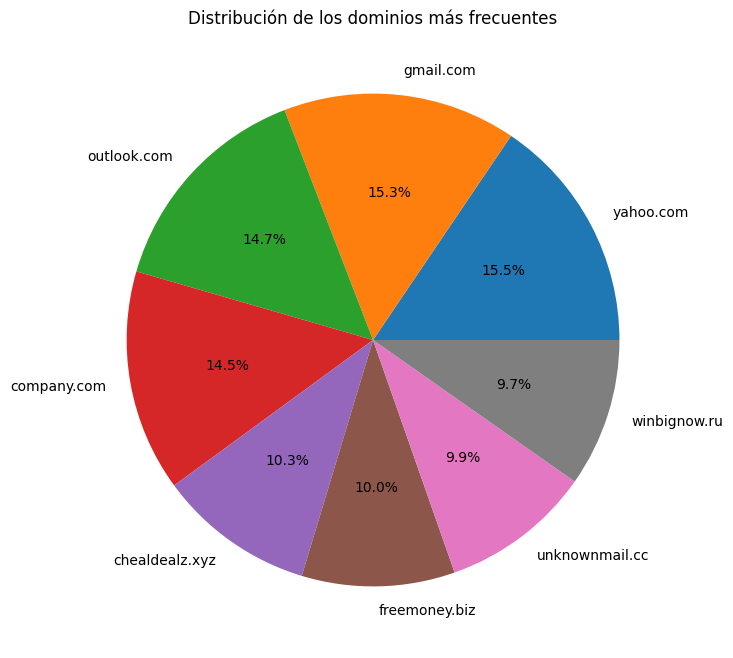

In [ ]:
top_subjects = email['sender_domain'].value_counts().head(10)

plt.figure(figsize=(8,8))
plt.pie(
    top_subjects,
    labels=top_subjects.index,
    autopct='%1.1f%%'
)

plt.title('Distribución de los dominios más frecuentes')
plt.show()

Se observa que el dominio yahoo.com posee la mayor participación, representando el 15.5 % del total de correos analizados. Muy cerca se encuentran gmail.com con un 15.3 % y outlook.com con un 14.7 %, lo que evidencia una alta presencia de proveedores de correo ampliamente utilizados.

Asimismo, el dominio company.com concentra el 14.5 % de los registros, manteniendo una participación similar a los principales dominios legítimos del conjunto de datos.

Por otro lado, dominios como chealdealz.xyz (10.3 %), freemoney.biz (10.0 %), unknownmail.cc (9.9 %) y winbignow.ru (9.7 %) presentan menores proporciones. Estos dominios poseen nombres asociados a promociones, ofertas o sitios poco convencionales, características frecuentemente relacionadas con correos spam o potencialmente fraudulentos.

En general, la distribución de dominios se encuentra relativamente equilibrada, aunque es posible distinguir diferencias entre dominios asociados a servicios de correo legítimos y aquellos con características más sospechosas. Esto sugiere que la variable sender_domain podría aportar información relevante para la clasificación de correos electrónicos spam y no spam.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.10 Exploración de variable sender_reputation_score** </FONT>

Se realiza la exploración de la variable `sender_reputation_score`

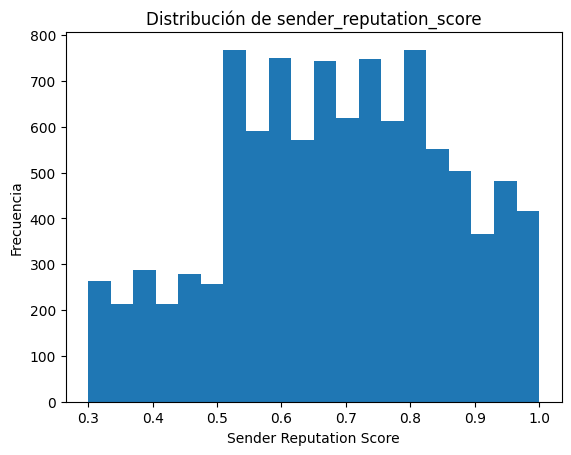

In [ ]:
plt.hist(email['sender_reputation_score'], bins=20)
plt.xlabel('Sender Reputation Score')
plt.ylabel('Frecuencia')
plt.title('Distribución de sender_reputation_score')
plt.show()

A partir de la gráfica se observa que la mayor concentración de correos se encuentra en valores de reputación media y media-alta, particularmente entre 0.5 y 0.85. En este intervalo se presentan las frecuencias más elevadas, superando en algunos casos los 700 correos por segmento, lo que indica que la mayoría de los remitentes poseen niveles de reputación relativamente favorables.

Por otro lado, los extremos de la distribución presentan una menor cantidad de observaciones. En el rango de reputación baja, entre 0.3 y 0.5, las frecuencias se mantienen inferiores a los 300 correos, evidenciando una menor presencia de remitentes con baja confiabilidad.
Asimismo, en los valores más altos de reputación, entre 0.85 y 1.0, se observa una disminución gradual en la frecuencia, con cantidades aproximadas entre 350 y 500 correos. Esto sugiere que, aunque existen remitentes con reputación excelente, estos aparecen con menor frecuencia dentro del dataset.

En términos generales, la distribución presenta una concentración importante en valores intermedios-altos de reputación, lo que podría resultar relevante para modelos de clasificación, ya que la reputación del remitente puede influir significativamente en la identificación de correos spam o legítimos.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.11 Exploración de variable email_hour** </FONT>

Se realiza la exploración de la variable `email_hour`

Text(0.5, 1.0, 'Distribución de correos por hora')

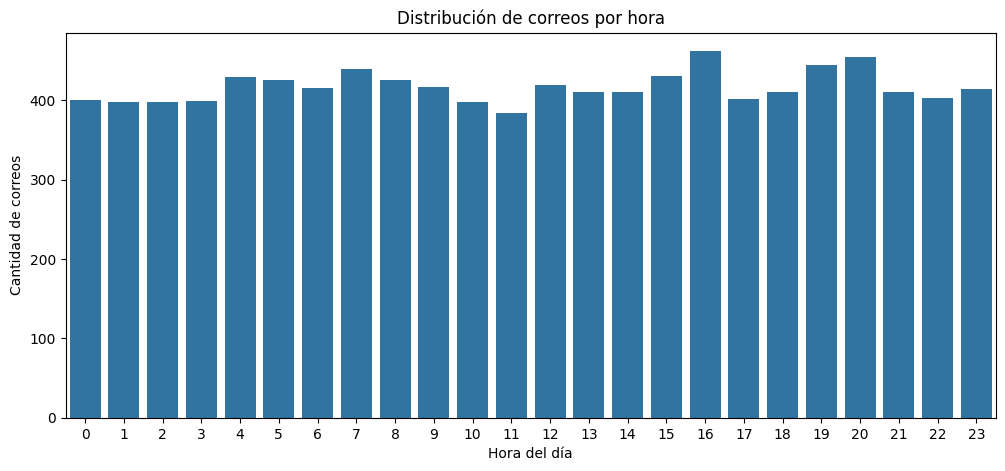

In [ ]:
plt.figure(figsize=(12,5))

sns.countplot(x='email_hour', data=email)

plt.xlabel('Hora del día')
plt.ylabel('Cantidad de correos')
plt.title('Distribución de correos por hora')


A partir de la gráfica se observa una distribución bastante homogénea y estable, donde el volumen de correos por hora se mantiene aproximadamente entre 380 y 460 registros. El punto de mayor actividad se presenta alrededor de las 16 horas, superando ligeramente los 450 correos, mientras que el menor número de envíos se registra cerca de las 11 horas, con una frecuencia apenas inferior a los 400 correos.

En general, no se evidencian diferencias marcadas entre horarios diurnos, nocturnos o laborales, ya que el flujo de correos permanece relativamente constante durante todo el día. Este comportamiento contrasta con los patrones habituales de comunicación humana, en los cuales normalmente existen picos de actividad durante horarios laborales y una disminución significativa durante la madrugada.
La regularidad observada en la distribución podría sugerir la presencia de procesos automatizados de envío de correos electrónicos, como sistemas automáticos, scripts o campañas masivas de spam, debido a la ausencia de variaciones naturales en el tráfico.

Por tanto, la variable email_hour podría aportar información relevante para identificar comportamientos anómalos o automatizados dentro del conjunto de datos.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.12 Exploración de variable email_day_of_week** </FONT>

Se realiza la exploración de la variable `email_day_of_week`

Text(0.5, 1.0, 'Distribución de correos por día')

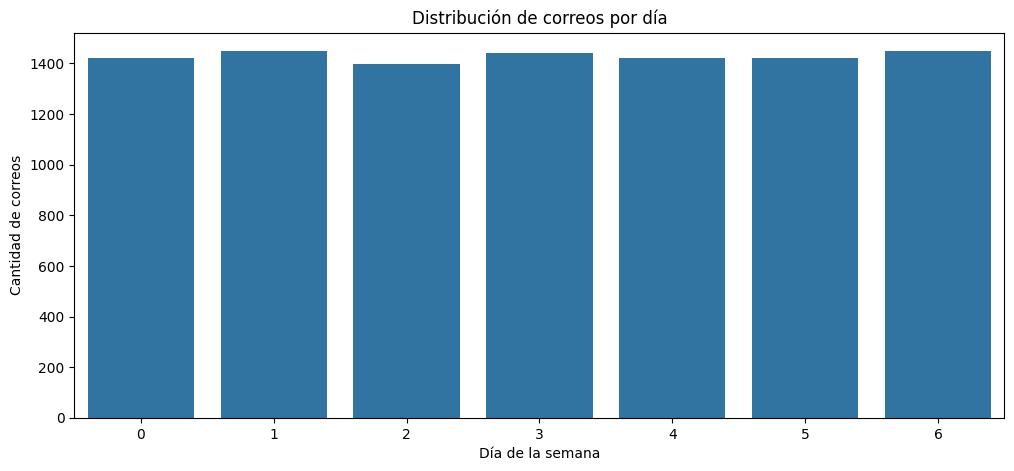

In [ ]:
plt.figure(figsize=(12,5))

sns.countplot(x='email_day_of_week', data=email)

plt.xlabel('Día de la semana')
plt.ylabel('Cantidad de correos')
plt.title('Distribución de correos por día')

En términos generales, la distribución presenta un comportamiento bastante uniforme, ya que la mayoría de los días registran aproximadamente 1400 correos electrónicos. Esto indica que el volumen de envíos se mantiene relativamente constante a lo largo de la semana, sin variaciones extremadamente marcadas.

Sin embargo, se observa que el día identificado con el valor 2 presenta la menor cantidad de correos enviados, mostrando una ligera disminución respecto a los demás días. Por otro lado, los días 1, 3 y 6 concentran las frecuencias más altas dentro de la distribución, aunque las diferencias siguen siendo moderadas.

La estabilidad observada en el flujo de correos durante todos los días de la semana podría sugerir un comportamiento automatizado en los envíos, ya que no se evidencian cambios significativos entre días laborales y fines de semana. En escenarios de comunicación humana normal, suele esperarse una reducción en la actividad durante ciertos días o periodos específicos.

Por tanto, la variable `email_day_of_week` podría aportar información útil para detectar patrones de envío automatizados o asociados a campañas masivas de spam dentro del dataset.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.13 Exploración de variable is_weekend** </FONT>

Se realiza la exploración de la variable `is_weekend`

In [ ]:
print(email['is_weekend'].value_counts())

is_weekend
0    7129
1    2871
Name: count, dtype: int64


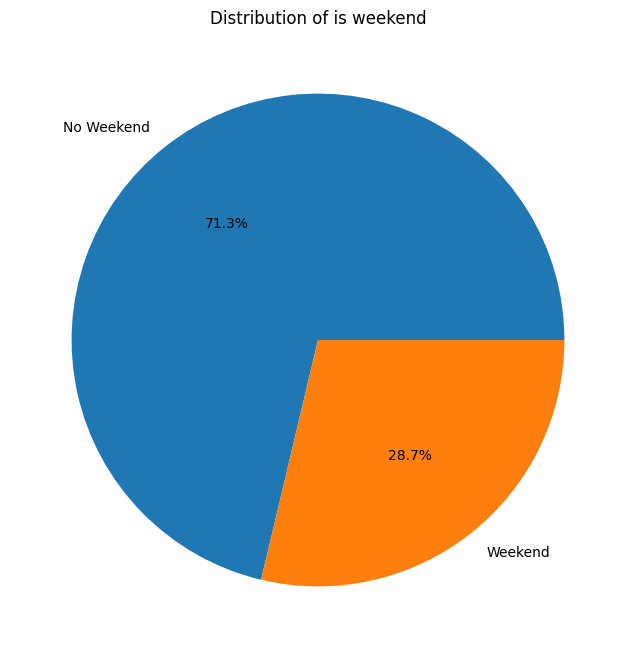

In [ ]:
suspicious_link_counts = email['is_weekend'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    suspicious_link_counts,
    labels=['No Weekend', 'Weekend'],
    autopct='%1.1f%%'
)

plt.title('Distribution of is weekend')
plt.show()

La variable `is_weekend` permite identificar si un correo electrónico fue enviado durante el fin de semana o en un día laboral. A partir de los datos observados, se evidencia que 7129 correos corresponden a días entre semana, mientras que 2871 fueron enviados durante el fin de semana.
En términos porcentuales, aproximadamente el 71.3 % de los correos fueron enviados en días laborales y el 28.7 % durante fines de semana. Esta diferencia resulta coherente con una mayor actividad de envío en días hábiles; sin embargo, la presencia considerable de correos durante fines de semana podría estar asociada a procesos automatizados o campañas masivas de envío.


In [ ]:
pd.crosstab(
    email['email_day_of_week'],
    email['is_weekend']
)

is_weekend,0,1
email_day_of_week,,
0,1420,0
1,1449,0
2,1397,0
3,1440,0
4,1423,0
5,0,1423
6,0,1448


In [ ]:
# Eliminar la variable has_attachment
email.drop(columns=['is_weekend'], inplace=True)

# Verificar columnas restantes
print(email.columns)

Index(['subject', 'num_words', 'num_characters', 'num_links',
       'has_suspicious_link', 'num_attachments', 'sender_domain',
       'sender_reputation_score', 'email_hour', 'email_day_of_week',
       'num_recipients', 'contains_money_terms', 'contains_urgency_terms',
       'label'],
      dtype='object')


Posteriormente, se realizó una tabla cruzada entre las variables `is_weekend` y `email_day_of_week `con el fin de analizar la relación entre ambas variables. A partir de este análisis se observó que `is_weekend` depende directamente del valor registrado en email_day_of_week, ya que los días correspondientes al fin de semana generan automáticamente el valor 1, mientras que los demás días toman el valor 0.
Debido a esta relación directa y redundante entre ambas variables, se decidió eliminar `is_weekend` y conservar únicamente `email_day_of_week`, dado que esta última proporciona información más detallada sobre el día específico en que fue enviado cada correo electrónico.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.14 Exploración de variable num_recipients** </FONT>

Se realiza la exploración de la variable `num_recipients`

Text(0.5, 1.0, 'Distribución de correos por número de destinatarios')

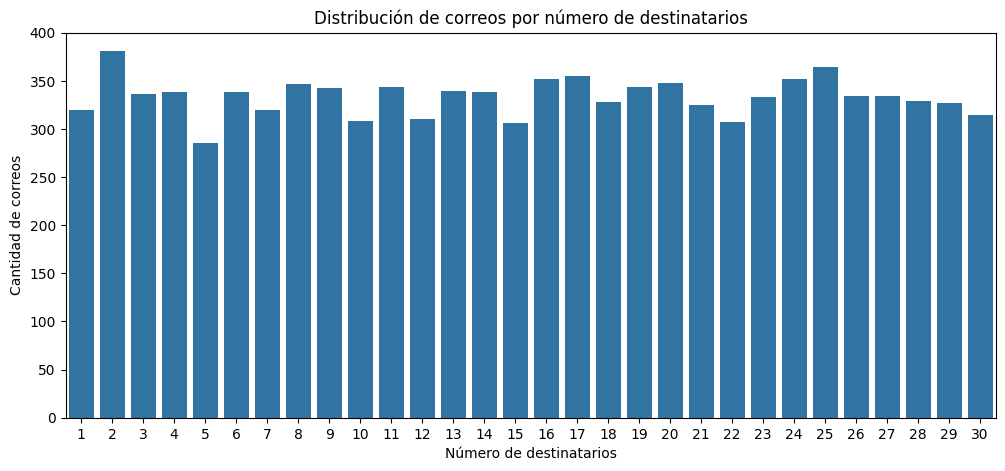

In [ ]:
plt.figure(figsize=(12,5))

sns.countplot(x='num_recipients', data=email)

plt.xlabel('Número de destinatarios')
plt.ylabel('Cantidad de correos')
plt.title('Distribución de correos por número de destinatarios')

A partir de la gráfica se observa una distribución relativamente uniforme y constante, donde la frecuencia de correos se mantiene aproximadamente entre 300 y 360 registros para la mayoría de las cantidades de destinatarios. Esto indica que no existe una concentración marcada en un número específico de receptores.

El valor más alto se presenta en los correos enviados a 2 destinatarios, alcanzando cerca de 380 observaciones, mientras que la menor frecuencia corresponde a los mensajes con 5 destinatarios, situándose ligeramente por debajo de los 300 correos.

En términos generales, la distribución presenta un comportamiento bastante homogéneo a lo largo de todo el rango de destinatarios. Este patrón resulta poco común en escenarios de comunicación humana normal, donde típicamente predominan los correos dirigidos a uno o pocos destinatarios y disminuyen progresivamente aquellos enviados a grupos más grandes.

La ausencia de variaciones significativas y la uniformidad observada podrían sugerir la existencia de procesos automatizados de envío, como campañas masivas de spam o sistemas controlados por software, en los cuales la cantidad de destinatarios se distribuye de manera más equilibrada.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.15 Exploración de variable contains_money_terms** </FONT>

Se realiza la exploración de la variable `contains_money_terms`

In [ ]:
print(email['contains_money_terms'].value_counts())

contains_money_terms
0    6015
1    3985
Name: count, dtype: int64


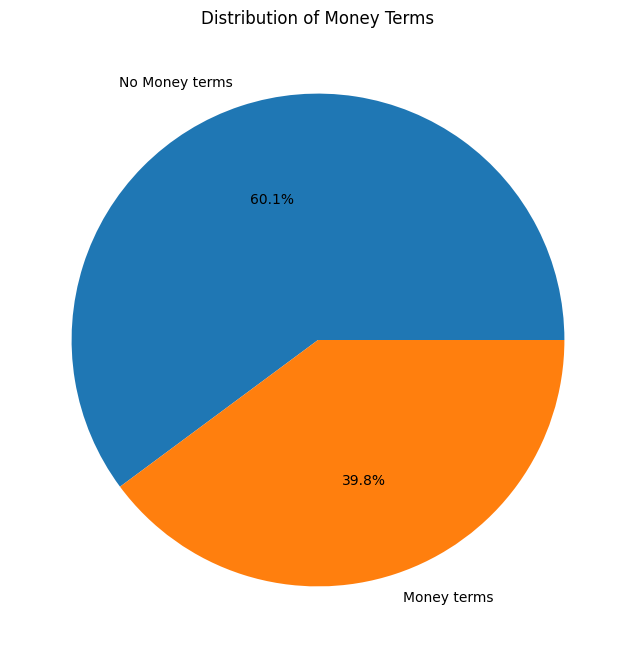

In [ ]:
suspicious_link_counts = email['contains_money_terms'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    suspicious_link_counts,
    labels=['No Money terms', 'Money terms'],
    autopct='%1.1f%%'
)

plt.title('Distribution of Money Terms')
plt.show()

La variable `contains_money_terms` indica si el correo electrónico contiene términos relacionados con dinero, premios, ganancias o incentivos económicos.

A partir de los datos observados, se identifica que 6015 correos electrónicos no contienen términos asociados al dinero, lo que representa aproximadamente el 60.1 % del total del dataset. Por otro lado, 3985 correos sí incluyen este tipo de palabras o expresiones, equivalentes al 39.8 % de las observaciones.
Aunque la mayoría de los correos no presenta términos monetarios, la proporción de mensajes que sí los contienen resulta considerablemente alta. Este comportamiento podría estar relacionado con campañas promocionales, publicidad o posibles correos spam, ya que este tipo de mensajes suele utilizar palabras asociadas a dinero, premios u ofertas para captar la atención de los usuarios.

En general, la variable `contains_money_terms` podría representar una característica relevante para los modelos de clasificación, debido a la posible relación entre el uso de términos monetarios y la detección de correos electrónicos fraudulentos o no deseados.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.16 Exploración de variable contains_urgency_terms** </FONT>

Se realiza la exploración de la variable `contains_urgency_terms`

In [ ]:
print(email['contains_urgency_terms'].value_counts())

contains_urgency_terms
0    5007
1    4993
Name: count, dtype: int64


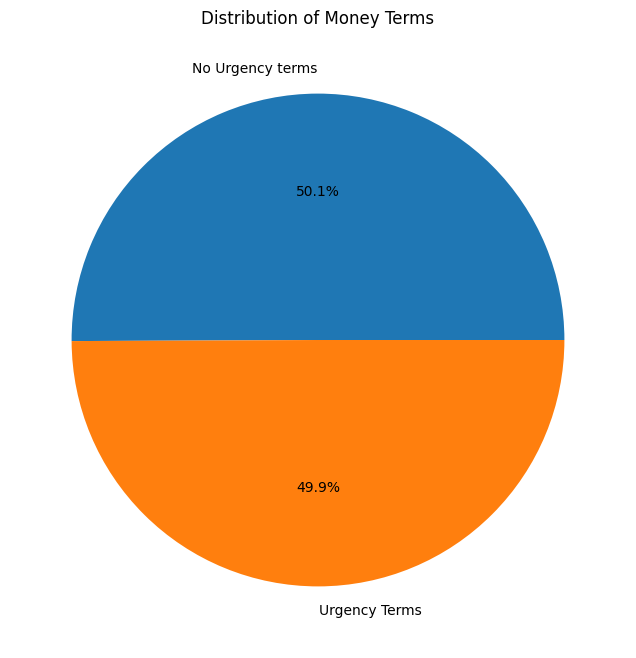

In [ ]:
suspicious_link_counts = email['contains_urgency_terms'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    suspicious_link_counts,
    labels=['No Urgency terms', 'Urgency Terms'],
    autopct='%1.1f%%'
)

plt.title('Distribution of Money Terms')
plt.show()

La variable `contains_urgency_terms` permite identificar si un correo electrónico contiene términos asociados con urgencia, presión o necesidad inmediata de acción.

A partir de los datos observados, se evidencia una distribución prácticamente equilibrada entre ambas categorías. En total, 5007 correos electrónicos no contienen términos de urgencia, lo que representa aproximadamente el 50.1 % del dataset, mientras que 4993 correos sí incluyen este tipo de expresiones, equivalentes al 49.9 % de las observaciones.

Esta distribución muestra que la presencia de palabras relacionadas con urgencia es muy frecuente dentro del conjunto de datos. Expresiones como “urgent”, “now”, “limited time” o similares suelen utilizarse comúnmente en campañas de spam, phishing y publicidad masiva con el objetivo de generar presión o incentivar una respuesta rápida por parte del usuario.

Debido a la alta presencia de este tipo de términos y a la relación que pueden tener con comportamientos sospechosos, la variable contains_urgency_terms podría aportar información relevante para la clasificación y detección de correos electrónicos spam.

#### <FONT SIZE=5 COLOR="purple"> **1.2.2.17 Exploración de variable label** </FONT>

Se realiza la exploración de la variable `label`

In [ ]:
print(email['label'].value_counts())

label
0    6005
1    3995
Name: count, dtype: int64


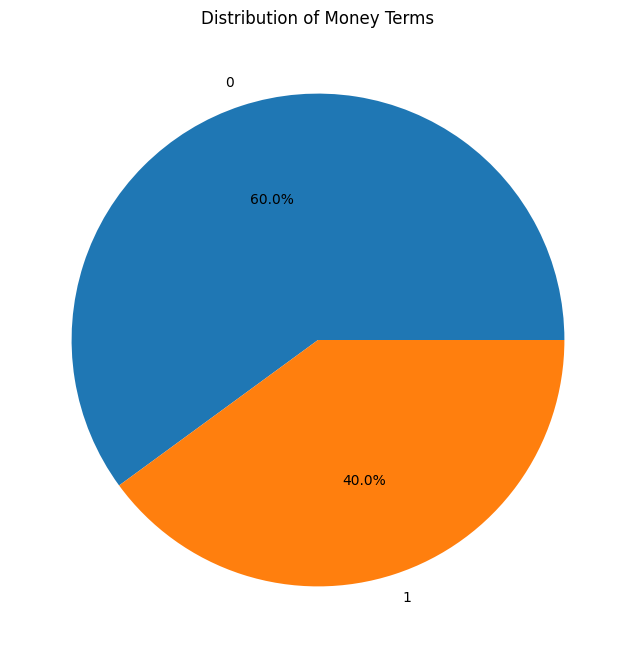

In [ ]:
suspicious_link_counts = email['label'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(
    suspicious_link_counts,
    labels=['0', '1'],
    autopct='%1.1f%%'
)

plt.title('Distribution of Money Terms')
plt.show()

La variable `label` corresponde a la clasificación objetivo del dataset, donde el valor 0 representa correos legítimos (no spam) y el valor 1 corresponde a correos spam.

A partir de los datos observados, se identifica que 6005 correos electrónicos pertenecen a la categoría no spam, lo que representa aproximadamente el 60 % del total del dataset. Por otro lado, 3995 correos fueron clasificados como spam, equivalentes al 40 % de las observaciones.

La distribución de clases muestra un conjunto de datos relativamente balanceado, aunque con una mayor proporción de correos legítimos. Esta diferencia no es excesivamente marcada, por lo que el dataset resulta adecuado para tareas de clasificación supervisada sin presentar un desbalance severo entre categorías.

Además, la presencia de una cantidad considerable de correos spam permite que los modelos de machine learning puedan aprender patrones relevantes asociados a mensajes fraudulentos, promociones masivas o campañas automatizadas de envío de correos electrónicos.

In [ ]:
# Verificar columnas restantes
print(email.columns)

Index(['subject', 'num_words', 'num_characters', 'num_links',
       'has_suspicious_link', 'num_attachments', 'sender_domain',
       'sender_reputation_score', 'email_hour', 'email_day_of_week',
       'num_recipients', 'contains_money_terms', 'contains_urgency_terms',
       'label'],
      dtype='object')


### <FONT SIZE=5 COLOR="purple"> **1.2.3 Exploración de relaciones de las variables con label** </FONT>

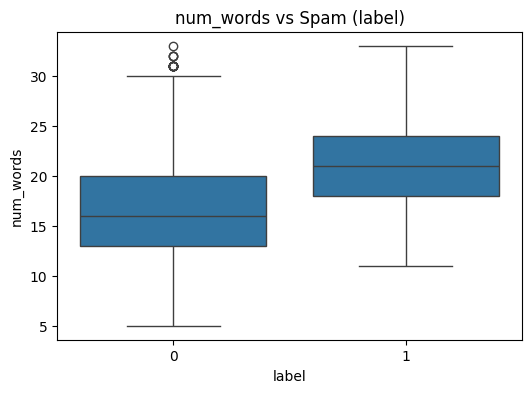

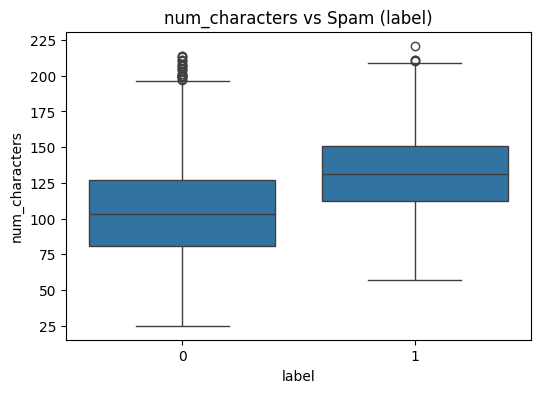

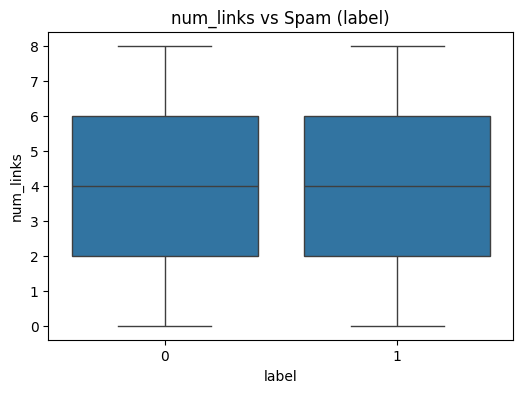

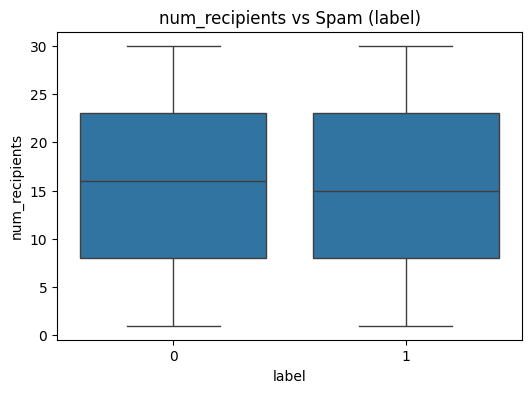

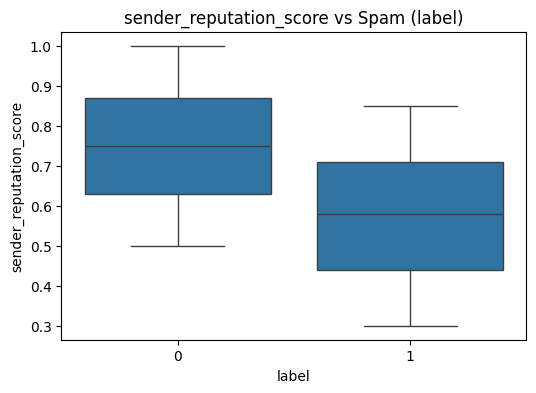

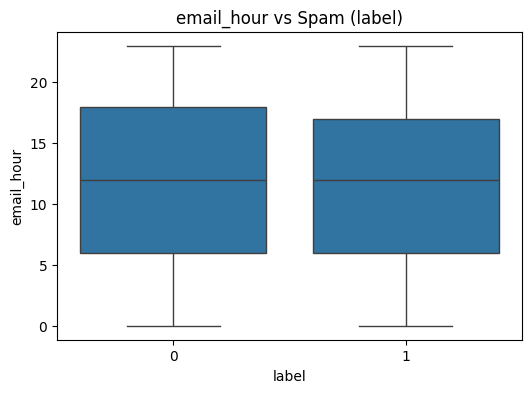

In [ ]:
num_vars = [
    "num_words",
    "num_characters",
    "num_links",
    "num_recipients",
    "sender_reputation_score",
    "email_hour"
]

for col in num_vars:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="label", y=col, data=email)
    plt.title(f"{col} vs Spam (label)")
    plt.show()

El gráfico de `num_words` muestra que los correos clasificados como 1 (spam) tienden a ser consistentemente más largos, registrando una mediana notablemente más alta (alrededor de 21 palabras) en comparación con el grupo 0 (aproximadamente 16 palabras), aunque este último grupo presenta una dispersión importante con varios valores atípicos de textos inusualmente extensos en su parte superior.

El gráfico de `num_characters` exhibe un comportamiento idéntico al de las palabras, desplazando la estructura del grupo 1 hacia un mayor número de caracteres con una distribución más compacta y homogénea, mientras que el grupo 0 concentra la mayoría de sus datos en valores bajos pero con múltiples excepciones atípicas que rozan los 225 caracteres.


El gráfico de `num_links` muestra dos cajas absolutamente idénticas para ambos grupos de `label`, compartiendo exactamente la misma mediana en 4 enlaces, el mismo rango intercuartílico (de 2 a 6) y los mismos límites en sus bigotes (de 0 a 8). Esta simetría perfecta demuestra visualmente que la cantidad de enlaces no discrimina en absoluto si un correo pertenece a una categoría o a otra.

De manera muy similar, el comportamiento de `num_recipients` resulta prácticamente indistinguible entre los correos legítimos (0) y sospechosos (1). Ambas distribuciones se extienden uniformemente desde 1 hasta 30 destinatarios y mantienen estructuras casi clonadas, con una variación insignificante en la mediana del grupo 1 que cae apenas un milímetro por debajo de la del grupo 0, confirmando que el volumen de destinatarios es irrelevante para clasificarlos.


Por su parte, el gráfico de `sender_reputation_score` destaca drásticamente al mostrar una separación clara y descendente entre ambos grupos. Mientras que los correos legítimos (0) concentran sus puntuaciones en la parte alta con una mediana de 0.75 y un límite superior que alcanza el 1.0, los correos del grupo 1 exhiben una notable caída en su reputación, con una mediana que desciende a 0.58 y un límite inferior que cae hasta 0.3, consolidándose como la variable con mayor poder de diferenciación visual y estadística.

Finalmente, el análisis de `email_hour` refuerza la falta de impacto de la variable temporal en este conjunto de datos. Las cajas de ambos grupos se solapan por completo, compartiendo una mediana idéntica justo en la hora 12 del día y distribuyendo el grueso de sus correos exactamente en el mismo rango (de las 6:00 a las 17:00-18:00 horas).



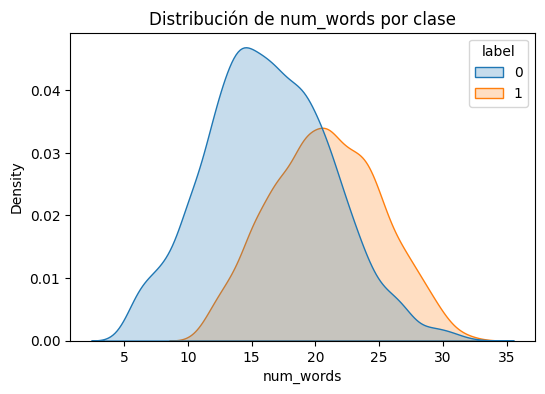

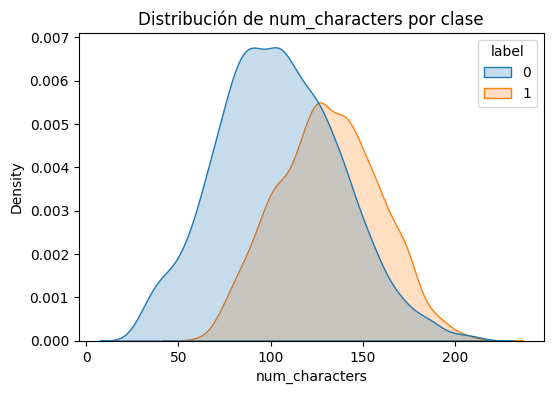

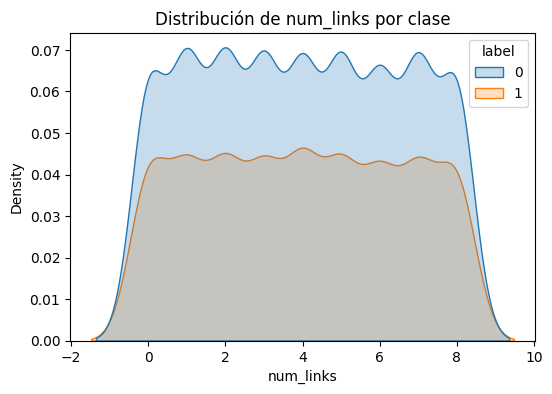

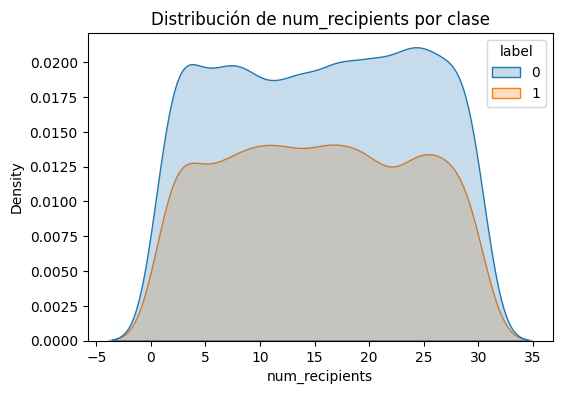

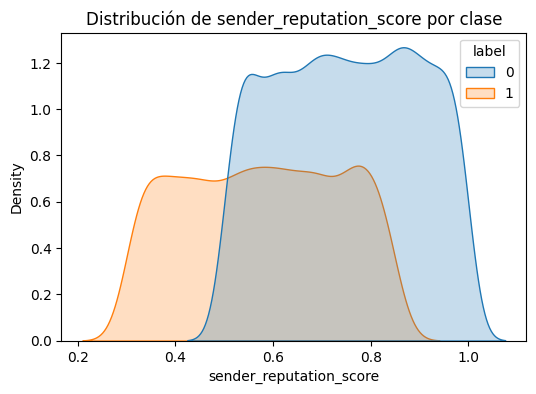

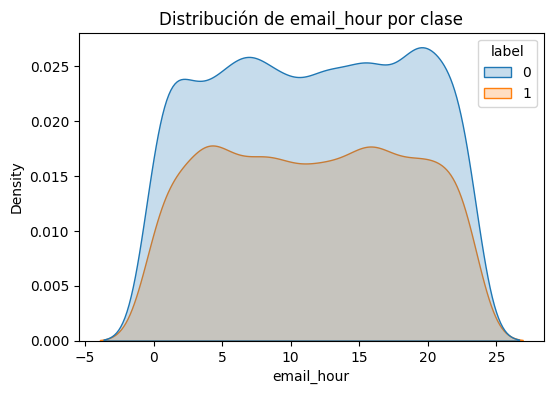

In [ ]:
for col in num_vars:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=email, x=col, hue="label", fill=True)
    plt.title(f"Distribución de {col} por clase")
    plt.show()

El gráfico de densidad de `num_words` muestra dos curvas campaneadas sutilmente desfasadas, donde la densidad de los correos legítimos (0) tiene su punto más alto alrededor de las 15 palabras y decae rápido, mientras que la curva de spam (1) se desplaza hacia la derecha, alcanzando su pico máximo cerca de las 21 palabras y confirmando una concentración mayor en textos más largos.

El gráfico de densidad de `num_characters` calca de forma exacta el comportamiento del volumen de palabras debido a su colinealidad, mostrando una curva azul (0) que predomina en la zona de textos más cortos con un pico cercano a los 100 caracteres, y una curva naranja (1) cuyo volumen principal se mueve en un bloque más avanzado entre los 125 y 150 caracteres.

El gráfico de densidad de `num_links` presenta un perfil chato y ondulado que es prácticamente un calco proporcional entre ambas clases a lo largo de todo el eje; las crestas y valles de los correos legítimos y del spam suben y bajan exactamente en los mismos puntos del 0 al 8, reafirmando visualmente que la densidad de enlaces no aporta distinción alguna.

El gráfico de densidad de `num_recipients` dibuja una meseta casi perfectamente plana y homogénea para ambas etiquetas, distribuyéndose de manera uniforme entre 0 y 30 destinatarios; el hecho de que las dos curvas mantengan la misma altura proporcional en todo el recorrido demuestra que la probabilidad de que sea spam no cambia según cuánta gente reciba el correo.

El gráfico de densidad de `sender_reputation_score` expone una clara asimetría que divide las clases; la distribución de los correos legítimos (0) se concentra fuertemente en puntuaciones altas entre 0.5 y 1.0, mientras que el grupo de spam (1) se ensancha visiblemente hacia la izquierda, abarcando un terreno exclusivo de baja reputación entre 0.3 y 0.5 donde los correos válidos prácticamente no existen.

El gráfico de densidad de `email_hour` cierra mostrando un comportamiento idéntico de solapamiento absoluto entre las dos curvas a lo largo de las 24 horas del día; tanto el grupo 0 como el grupo 1 se distribuyen con la misma densidad simétrica en todas las franjas horarias, confirmando que el momento del envío es incapaz de separar los correos legítimos del spam.

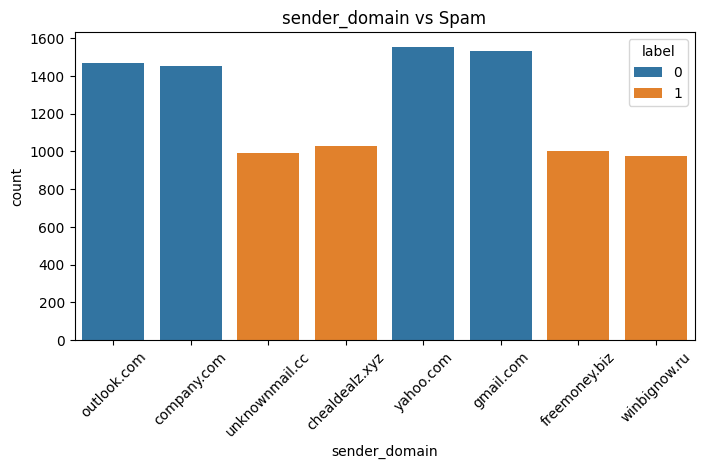

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


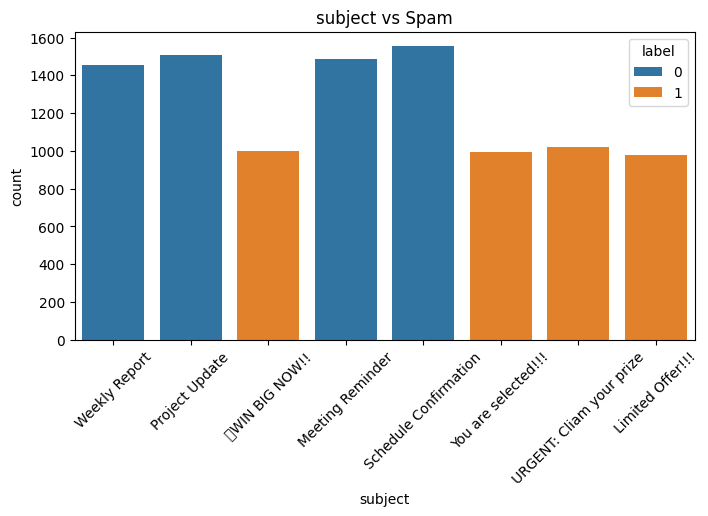

In [ ]:
cat_vars = [
    "sender_domain",
    "subject"
]

for col in cat_vars:
    plt.figure(figsize=(8,4))
    sns.countplot(data=email, x=col, hue="label")
    plt.title(f"{col} vs Spam")
    plt.xticks(rotation=45)
    plt.show()


El gráfico de `sender_domain` revela una separación perfecta y absoluta entre los dominios emisores y las categorías de label. Los dominios corporativos o comerciales masivos tradicionales (outlook.com, company.com, yahoo.com, gmail.com) pertenecen exclusivamente al grupo 0 (correos legítimos) con volúmenes altos que rozan o superan los 1400 registros, mientras que los dominios extraños o con nombres sospechosos (unknownmail.cc, chealdealz.xyz, freemoney.biz, winbignow.ru) se asocian de forma única al grupo 1 (spam), con conteos uniformes cercanos a los 1000 registros por dominio.

El gráfico de `subject`(asunto del correo) muestra un comportamiento idéntico de segmentación total y directa respecto a la variable objetivo. Los asuntos de carácter formal, laboral o informativo como "Weekly Report", "Project Update" y "Meeting Reminder" se clasifican al 100% dentro del grupo de correos legítimos (0), registrando picos de hasta 1500 instancias; por el contrario, los títulos agresivos, promocionales o con exceso de signos de exclamación (como "WIN BIG NOW!!", "Confirmation", "You have been selected!!!" o "Claim your prize") caen exclusivamente en el grupo 1 (spam), consolidándose junto al dominio como un predictor categórico infalible para el modelo.

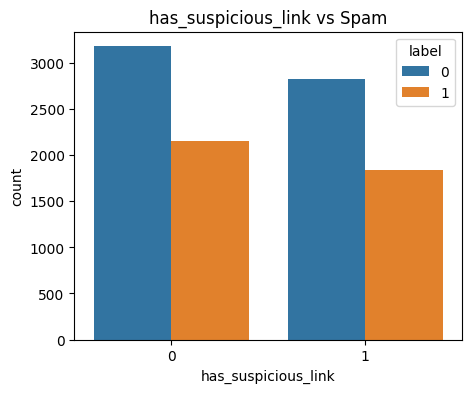

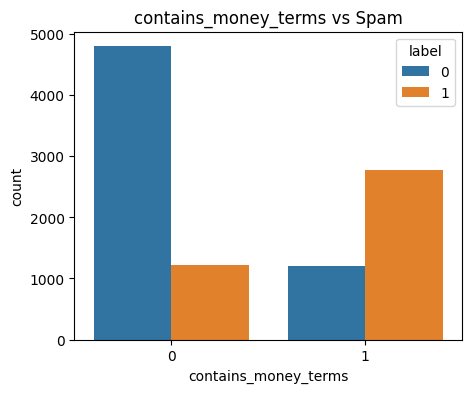

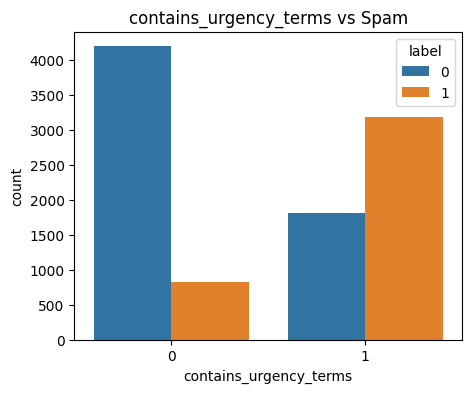

In [ ]:
bool_vars = ['has_suspicious_link', 'contains_money_terms', 'contains_urgency_terms']

for col in bool_vars:
    plt.figure(figsize=(5,4))
    sns.countplot(data=email, x=col, hue="label")
    plt.title(f"{col} vs Spam")
    plt.show()



El gráfico de `has_suspicious_link` muestra una distribución bastante similar en ambos escenarios (0 y 1), lo que indica que la presencia de un enlace sospechoso por sí sola no inclina la balanza de forma contundente. Tanto si el correo no tiene enlaces dudosos (0) como si los tiene (1), la proporción de correos legítimos (azul) se mantiene superior a la de spam (naranja), reduciéndose ligeramente el volumen general de correos en la categoría que sí los incluye.

El gráfico de `contains_money_terms` revela un patrón de comportamiento muy claro e invertido; cuando el correo no incluye términos financieros (0), la inmensa mayoría de los mensajes pertenecen a la categoría legítima (rozando los 4800 registros). En contraste, cuando el correo sí contiene palabras relacionadas con dinero (1), la tendencia se invierte drásticamente, cuadruplicando la cantidad de correos clasificados como spam (naranja) frente a los correos legítimos.

El gráfico de `contains_urgency_terms` exhibe un impacto predictivo igual de contundente en la clasificación. En ausencia de términos de urgencia (0), los correos legítimos dominan de forma masiva el conteo con más de 4000 registros frente a un grupo de spam muy reducido; sin embargo, al activarse la presencia de urgencia (1), los correos de spam se disparan notablemente hasta superar las 3000 instancias, demostrando que la presión temporal en el texto es un fuerte indicador de correo no deseado.

### <FONT SIZE=5 COLOR="purple"> **1.2.4 Tabla de correlaciones** </FONT>

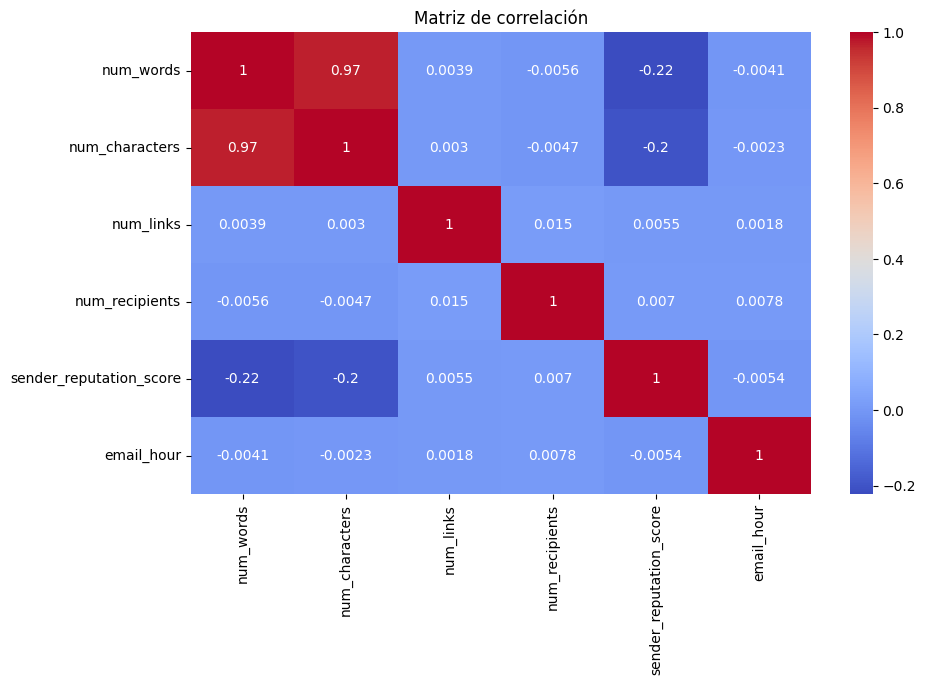

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(email[num_vars].corr(), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

Al analizar la gráfica se observa el comportamiento interno de las variables independientes, la relación más evidente ocurre entre el número de palabras y el número de caracteres, que alcanzan un coeficiente de 0.97. Esta correlación positiva casi perfecta confirma que ambas variables comparten la misma información matemática.

Fuera de ese par redundante, el resto de las variables predictoras muestran una independencia casi absoluta entre sí, con coeficientes que rozan el cero. Por ejemplo, la cantidad de enlaces en el correo (num_links) no tiene ninguna relación con el número de destinatarios (0.015), ni con la hora de envío (0.0018), ni con la longitud del texto. Lo mismo ocurre con la hora del correo (email_hour) y el número de destinatarios (num_recipients), cuyos valores de correlación con las demás variables son insignificantes, demostrando que son eventos estadísticamente aislados dentro de los datos.

El único comportamiento interno que muestra un matiz levemente distinto es el de la reputación del remitente (sender_reputation_score). Esta variable presenta una correlación negativa muy ligera con el tamaño del correo, registrando -0.22 con el número de palabras y -0.20 con el número de caracteres. Aunque es una relación débil, sugiere una pequeña tendencia en el conjunto de datos donde los remitentes con peor reputación (puntuaciones más bajas) tienden a enviar correos ligeramente más extensos, o viceversa, siendo este el único patrón cruzado llamativo en una matriz que, por lo demás, está llena de variables completamente desconectadas entre sí.

## <FONT SIZE=5 COLOR="purple"> **1.3 Aplicación de modelos** </FONT>

En primer lugar separamos las variables predictoras de la variable objetivo, en este caso la variable objetivo es `label`

In [ ]:
X = email.drop('label', axis=1)#Variables predictoras
y = email['label']#Variable objetivo

Ahora separamos las variables categóricas de las numéricas para poder escalar las variables númericas y decodificar las variables categóricas

In [ ]:
#Variables numericas
variables_num = [
    'num_words',
    'num_characters',
    'num_links',
    'num_attachments',
    'sender_reputation_score',
    'email_hour',
    'email_day_of_week',
    'num_recipients'
]
#Variables categoricas
variables_cat = [
    'subject',
    'sender_domain',
    'has_suspicious_link',
    'contains_money_terms',
    'contains_urgency_terms'
]


Separamos los datos en entrenamiento prueba, el 70% de los datos(7000) son para entrenar el modelo y el 30%(3000) son para probar el modelo

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    random_state=0,
    test_size=0.3
)

Ahora se realiza el preprocesamiento de los datos utilizando ColumnTransformer. Para las variables numéricas se aplica StandardScaler, el cual estandariza los datos para que tengan media 0 y desviación estándar 1, evitando que variables con escalas más grandes dominen el modelo.
Por otro lado, las variables categóricas se transforman mediante OneHotEncoder, convirtiendo cada categoría en variables binarias. Además, se utiliza drop='first' para evitar redundancia entre categorías y handle_unknown='ignore' para manejar categorías no vistas previamente.
Finalmente, el preprocesador se ajusta con el conjunto de entrenamiento usando fit_transform y posteriormente se aplica a el conjunto prueba mediante transform. Esto garantiza que todos los conjuntos sean transformados de manera consistente utilizando únicamente la información aprendida del conjunto de entrenamiento.

### <FONT SIZE=5 COLOR="purple"> **1.3.1 Regresión logística** </FONT>

Ahora escalamos las variables numericas y codificamos las categoricas para poder aplicar un modelo de regresión logística

In [ ]:
#Preprocesamiento
preprocessor1 = ColumnTransformer(transformers=[

    ('num',
     StandardScaler(),
     variables_num),

    ('cat',
     OneHotEncoder(
         handle_unknown='ignore',
         drop='first'
     ),
     variables_cat)

])

X_train_s = preprocessor1.fit_transform(X_train)

X_test_s = preprocessor1.transform(X_test)

Ahora se entrena un modelo de regresión logística, se hacen las predicciones y se calculan las matrices de confusión para los datos de entrenamiento y prueba

----------------Matrices de Confusión (Train vs Test)------------------- 



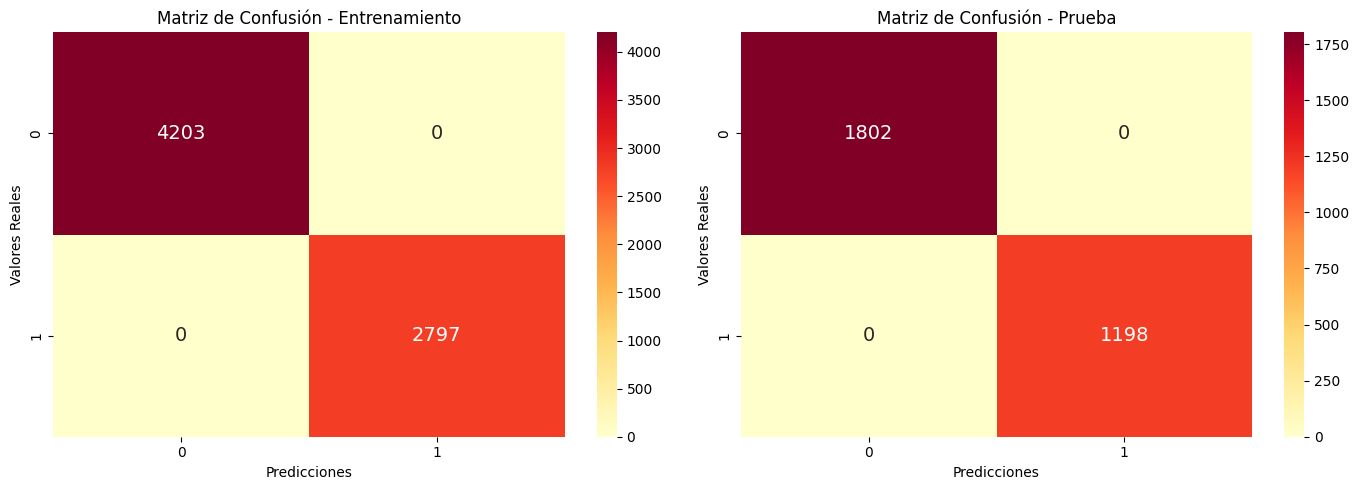


----------------Métricas de Evaluación------------------- 

               accuracy  recall  specificidad  precision   f1
Reg_Log_Train       1.0     1.0           1.0        1.0  1.0
Reg_Log_Test        1.0     1.0           1.0        1.0  1.0


In [ ]:
modelo_log = LogisticRegression(random_state=0)
modelo_log.fit(X_train_s, y_train)

# Predicciones (en ambos conjuntos para comparar)
y_pred_train_log = modelo_log.predict(X_train_s)
y_pred_test_log = modelo_log.predict(X_test_s)

# Visualización de Matrices de Confusión
print("----------------Matrices de Confusión (Train vs Test)------------------- \n")
cm_train = confusion_matrix(y_train, y_pred_train_log)
cm_test = confusion_matrix(y_test, y_pred_test_log)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz Train
sns.heatmap(pd.DataFrame(cm_train), annot=True, fmt='g', cmap='YlOrRd', annot_kws={'size':14}, ax=axes[0])
axes[0].set_title('Matriz de Confusión - Entrenamiento')
axes[0].set_xlabel('Predicciones')
axes[0].set_ylabel('Valores Reales')

# Matriz Test
sns.heatmap(pd.DataFrame(cm_test), annot=True, fmt='g', cmap='YlOrRd', annot_kws={'size':14}, ax=axes[1])
axes[1].set_title('Matriz de Confusión - Prueba')
axes[1].set_xlabel('Predicciones')
axes[1].set_ylabel('Valores Reales')

plt.tight_layout()
plt.show()

# Tabla Comparativa de Métricas
print("\n----------------Métricas de Evaluación------------------- \n")
metrics = ["accuracy", "recall", "specificidad", "precision", "f1"]
pos_label_name = 1

# Función auxiliar para especificidad
def get_specificity(y_true, y_pred, label):
    cm = confusion_matrix(y_true, y_pred)
    # Asumiendo matriz 2x2: [[TN, FP], [FN, TP]]
    # Si 'Alta (>80)' es la clase positiva (1), la especificidad es TN / (TN + FP)
    return cm[0,0] / (cm[0,0] + cm[0,1])

# Valores Entrenamiento
values_train = [
    accuracy_score(y_train, y_pred_train_log),
    recall_score(y_train, y_pred_train_log, pos_label=pos_label_name),
    get_specificity(y_train, y_pred_train_log, pos_label_name),
    precision_score(y_train, y_pred_train_log, pos_label=pos_label_name),
    f1_score(y_train, y_pred_train_log, pos_label=pos_label_name)
]

# Valores Prueba
values_test = [
    accuracy_score(y_test, y_pred_test_log),
    recall_score(y_test, y_pred_test_log, pos_label=pos_label_name),
    get_specificity(y_test, y_pred_test_log, pos_label_name),
    precision_score(y_test, y_pred_test_log, pos_label=pos_label_name),
    f1_score(y_test, y_pred_test_log, pos_label=pos_label_name)
]

# Crear DataFrame Final
df_resumen = pd.DataFrame([values_train, values_test],
                          columns=metrics,
                          index=["Reg_Log_Train", "Reg_Log_Test"])

print(df_resumen)

Las gráficas presentan las matrices de confusión y las métricas de evaluación obtenidas con el modelo de regresión logística tanto en entrenamiento como en prueba.

En la matriz de entrenamiento se observa que las 4203 observaciones de la clase 0 y las 2797 observaciones de la clase 1 fueron clasificadas correctamente, sin registrar errores de predicción. De manera similar, en la matriz de prueba el modelo clasificó correctamente las 1802 observaciones de la clase 0 y las 1198 observaciones de la clase 1.

La ausencia total de valores fuera de la diagonal principal indica que no existieron falsos positivos ni falsos negativos, lo que confirma una clasificación perfecta en ambos conjuntos de datos.

Asimismo, la tabla de métricas muestra valores de 1.0 para accuracy, recall, specificity, precision y f1 tanto en entrenamiento como en prueba. Esto evidencia que el modelo logró identificar correctamente todas las observaciones del dataset.


### <FONT SIZE=5 COLOR="purple"> **1.3.2 Árboles de decisión** </FONT>

Ahora  codificamos las categoricas para poder aplicar un modelo de arboles de decisión

In [ ]:
preprocessor2 = ColumnTransformer(transformers=[

    ('cat',
     OneHotEncoder(handle_unknown='ignore', drop='first'),
     variables_cat)

], remainder='passthrough')


X_train_t = preprocessor2.fit_transform(X_train)
X_test_t = preprocessor2.transform(X_test)


Ahora se entrena un modelo de árboles de decisión, se hacen las predicciones y se calculan las matrices de confusión para los datos de entrenamiento y prueba


--------------- REPORTE TRAIN ----------------

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4203
           1       1.00      1.00      1.00      2797

    accuracy                           1.00      7000
   macro avg       1.00      1.00      1.00      7000
weighted avg       1.00      1.00      1.00      7000

--------------- REPORTE TEST ----------------

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1802
           1       0.99      1.00      1.00      1198

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



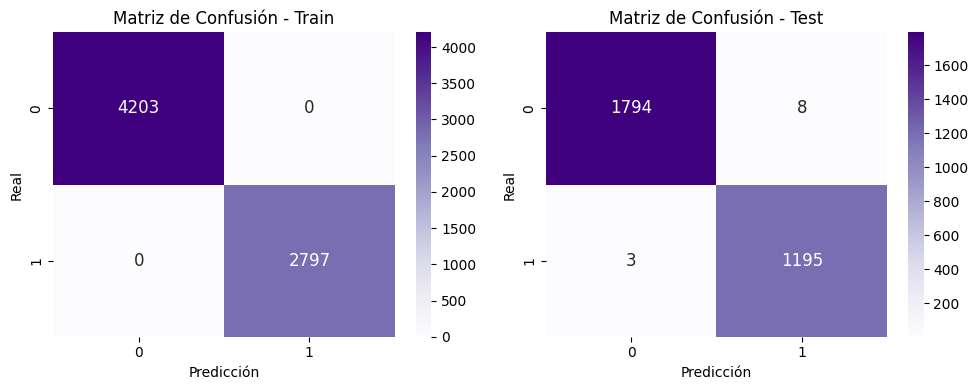

Profundidad del árbol: 17
Número de hojas: 40
            accuracy    recall  specificity  precision        f1
Tree_Train  1.000000  1.000000      1.00000    1.00000  1.000000
Tree_Test   0.996333  0.997496      0.99556    0.99335  0.995419


In [ ]:
model_tree = DecisionTreeClassifier(
    random_state=123
)

# entrenar modelo
model_tree.fit(X_train_t, y_train)

# train
y_pred_train_tree = model_tree.predict(X_train_t)

# test
y_pred_test_tree = model_tree.predict(X_test_t)

print("--------------- REPORTE TRAIN ----------------\n")
print(
    classification_report(
        y_train,
        y_pred_train_tree
    )
)
print("--------------- REPORTE TEST ----------------\n")
print(
    classification_report(
        y_test,
        y_pred_test_tree
    )
)

# MATRICES DE CONFUSIÓN
cm_train = confusion_matrix(
    y_train,
    y_pred_train_tree
)
cm_test = confusion_matrix(
    y_test,
    y_pred_test_tree
)
fig, axes = plt.subplots(1, 2, figsize=(10,4))
# TRAIN
sns.heatmap(
    cm_train,
    annot=True,
    fmt='g',
    cmap='Purples',
    annot_kws={'size':12},
    ax=axes[0]
)
axes[0].set_title('Matriz de Confusión - Train')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

# TEST
sns.heatmap(
    cm_test,
    annot=True,
    fmt='g',
    cmap='Purples',
    annot_kws={'size':12},
    ax=axes[1]
)

axes[1].set_title('Matriz de Confusión - Test')

axes[1].set_xlabel('Predicción')

axes[1].set_ylabel('Real')

plt.tight_layout()

plt.show()

print(
    f"Profundidad del árbol: {model_tree.get_depth()}"
)

print(
    f"Número de hojas: {model_tree.get_n_leaves()}"
)
metrics = [
    "accuracy",
    "recall",
    "specificity",
    "precision",
    "f1"
]


# función specificity

def get_specificity(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp)


# métricas train

values_train = [
    accuracy_score(y_train, y_pred_train_tree),
    recall_score(y_train, y_pred_train_tree),
    get_specificity(y_train, y_pred_train_tree),
    precision_score(y_train, y_pred_train_tree),
    f1_score(y_train, y_pred_train_tree)
]


# métricas test

values_test = [
    accuracy_score(y_test, y_pred_test_tree),
    recall_score(y_test, y_pred_test_tree),
    get_specificity(y_test, y_pred_test_tree),
    precision_score(y_test, y_pred_test_tree),
    f1_score(y_test, y_pred_test_tree)
]


# dataframe final

df_tree = pd.DataFrame(
    [values_train, values_test],
    columns=metrics,
    index=["Tree_Train", "Tree_Test"]
)

print(df_tree)

La imagen presenta los resultados obtenidos con el modelo de árboles de decisión tanto en entrenamiento como en prueba. En el conjunto de entrenamiento, el modelo alcanzó un desempeño perfecto, clasificando correctamente las 4203 observaciones de la clase 0 y las 2797 de la clase 1 sin cometer errores.

En el conjunto de prueba, el desempeño también fue muy alto. El modelo clasificó correctamente 1794 observaciones de la clase 0 y 1195 observaciones de la clase 1. Sin embargo, se registraron algunos errores de clasificación: 8 falsos positivos y 3 falsos negativos.
Las métricas obtenidas reflejan este excelente rendimiento, con un accuracy de aproximadamente 99.63 %, un recall de 99.75 %, una specificity de 99.56 %, una precision de 99.33 % y un F1-score cercano a 99.54 % en el conjunto de prueba.

Además, el árbol construido alcanzó una profundidad de 17 niveles y un total de 40 hojas terminales, lo que indica una estructura relativamente compleja capaz de capturar patrones detallados dentro de los datos.

En general, el modelo de árboles de decisión mostró una capacidad de clasificación extremadamente alta, aunque ligeramente inferior a la obtenida previamente con la regresión logística.

In [ ]:
print("Importancia de los predictores en el modelo")
print("-------------------------------------------")

# Get feature names after preprocessing
feature_names = preprocessor2.get_feature_names_out()

importancia_predictores = pd.DataFrame(
    {'predictor': feature_names,
     'importancia': model_tree.feature_importances_}
)
importancia_predictores.sort_values('importancia', ascending=False)

Importancia de los predictores en el modelo
-------------------------------------------


,predictor,importancia
21,remainder__sender_reputation_score,0.301174
15,cat__contains_money_terms_1,0.171363
20,remainder__num_attachments,0.078431
8,cat__sender_domain_freemoney.biz,0.066763
12,cat__sender_domain_winbignow.ru,0.064972
11,cat__sender_domain_unknownmail.cc,0.059485
7,cat__sender_domain_company.com,0.059307
13,cat__sender_domain_yahoo.com,0.046933
10,cat__sender_domain_outlook.com,0.042056
9,cat__sender_domain_gmail.com,0.041559


La tabla de importancia de predictores muestra que la variable más influyente en el modelo es `sender_reputation_score`, con una importancia de 0.301, lo que indica que la reputación del remitente es el factor más determinante para clasificar un correo como spam o no spam.

En segundo lugar, destaca la variable `contains_money_terms_1` con una importancia de 0.171, evidenciando que la presencia de palabras relacionadas con dinero tiene una fuerte relación con los correos maliciosos. También sobresalen variables como `num_attachments` y varios dominios sospechosos, especialmente `freemoney.biz`, `winbignow.ru` y `unknownmail.cc`, los cuales aportan una gran capacidad de discriminación al modelo.

Asimismo, algunos asuntos de correo asociados con mensajes fraudulentos, como *“You are selected!!!”*, *“🔥WIN BIG NOW!!”* y *“URGENT: Cliam your prize”*, presentan importancias relevantes, reforzando la idea de que los patrones de spam están fuertemente asociados con lenguaje promocional o urgente.

Por otro lado, variables como `email_hour`, `email_day_of_week`, `num_links`, `num_words` y ciertos asuntos informativos tienen una importancia prácticamente nula, lo que indica que aportan muy poca información para la clasificación del modelo.


### <FONT SIZE=5 COLOR="purple"> **1.3.3 Random forest** </FONT>


Ahora se entrena un modelo de random forest, se hacen las predicciones y se calculan las matrices de confusión para los datos de entrenamiento y prueba

--------------- REPORTE TRAIN ----------------

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4203
           1       1.00      1.00      1.00      2797

    accuracy                           1.00      7000
   macro avg       1.00      1.00      1.00      7000
weighted avg       1.00      1.00      1.00      7000

--------------- REPORTE TEST ----------------

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1802
           1       1.00      1.00      1.00      1198

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



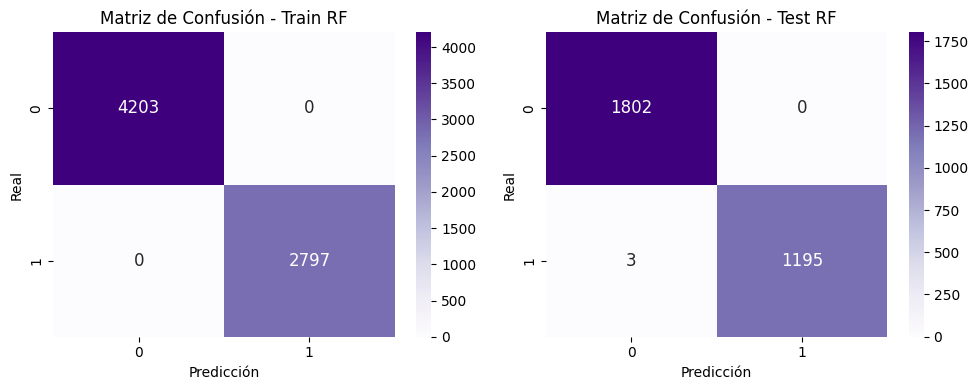

          accuracy    recall  specificity  precision        f1
RF_Train     1.000  1.000000          1.0        1.0  1.000000
RF_Test      0.999  0.997496          1.0        1.0  0.998746


In [ ]:
#modelo
model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=123
)

#entrenamiento
model_rf.fit(X_train_t, y_train)

#predicciones
y_pred_train_rf = model_rf.predict(X_train_t)
y_pred_test_rf = model_rf.predict(X_test_t)

print("--------------- REPORTE TRAIN ----------------\n")
print(
    classification_report(
        y_train,
        y_pred_train_rf
    )
)

print("--------------- REPORTE TEST ----------------\n")
print(
    classification_report(
        y_test,
        y_pred_test_rf
    )
)

# MATRICES DE CONFUSIÓN
cm_train = confusion_matrix(
    y_train,
    y_pred_train_rf
)

cm_test = confusion_matrix(
    y_test,
    y_pred_test_rf
)

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# TRAIN

sns.heatmap(
    cm_train,
    annot=True,
    fmt='g',
    cmap='Purples',
    annot_kws={'size':12},
    ax=axes[0]
)

axes[0].set_title('Matriz de Confusión - Train RF')

axes[0].set_xlabel('Predicción')

axes[0].set_ylabel('Real')

# TEST

sns.heatmap(
    cm_test,
    annot=True,
    fmt='g',
    cmap='Purples',
    annot_kws={'size':12},
    ax=axes[1]
)

axes[1].set_title('Matriz de Confusión - Test RF')

axes[1].set_xlabel('Predicción')

axes[1].set_ylabel('Real')

plt.tight_layout()

plt.show()

# MÉTRICAS

metrics = [
    "accuracy",
    "recall",
    "specificity",
    "precision",
    "f1"
]

# función specificity

def get_specificity(y_true, y_pred):

    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    return tn / (tn + fp)

# métricas train

values_train = [
    accuracy_score(y_train, y_pred_train_rf),
    recall_score(y_train, y_pred_train_rf),
    get_specificity(y_train, y_pred_train_rf),
    precision_score(y_train, y_pred_train_rf),
    f1_score(y_train, y_pred_train_rf)
]

# métricas test

values_test = [
    accuracy_score(y_test, y_pred_test_rf),
    recall_score(y_test, y_pred_test_rf),
    get_specificity(y_test, y_pred_test_rf),
    precision_score(y_test, y_pred_test_rf),
    f1_score(y_test, y_pred_test_rf)
]


df_rf = pd.DataFrame(
    [values_train, values_test],
    columns=metrics,
    index=["RF_Train", "RF_Test"]
)

print(df_rf)

Las gráficas muestra el desempeño del modelo de Random Forest en los conjuntos de entrenamiento y prueba. En entrenamiento, el modelo alcanzó una clasificación perfecta, identificando correctamente las 4203 observaciones de la clase 0 y las 2797 de la clase 1, sin errores de predicción.

En el conjunto de prueba, el rendimiento también fue sobresaliente. El modelo clasificó correctamente las 1802 observaciones de la clase 0 y 1195 observaciones de la clase 1. Únicamente se presentaron 3 falsos negativos y ningún falso positivo, lo que evidencia una capacidad de generalización muy alta.

Las métricas obtenidas confirman este comportamiento, alcanzando un accuracy cercano al 99.9 %, junto con valores prácticamente perfectos de precision, recall, specificity y F1-score. Esto indica que el modelo logra distinguir de manera muy eficiente entre correos spam y no spam.

En comparación con el árbol de decisión individual, el modelo Random Forest presenta un desempeño ligeramente superior y más robusto, ya que reduce los errores de clasificación gracias a la combinación de múltiples árboles de decisión.

## <FONT SIZE=5 COLOR="purple"> **1.4 Curva ROC** </FONT>

Se calculan las curvas ROC y se grafican para escoger el mejor modelo

AUC Regresión Logística: 1.0
AUC Árbol de Decisión: 0.9965281573617886
AUC Random Forest: 1.0


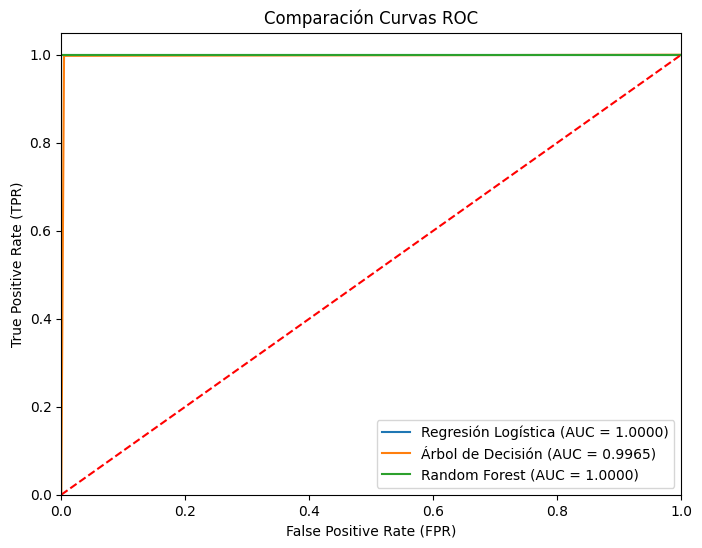

In [ ]:

# CURVAS ROC Y AUC PARA COMPARAR MODELOS


# Regresión logística
y_prob_log = modelo_log.predict_proba(X_test_s)[:,1]
# Árbol de decisión
y_prob_tree = model_tree.predict_proba(X_test_t)[:,1]
# Random Forest
y_prob_rf = model_rf.predict_proba(X_test_t)[:,1]

# AUC DE CADA MODELO
auc_log = roc_auc_score(y_test, y_prob_log)
auc_tree = roc_auc_score(y_test, y_prob_tree)
auc_rf = roc_auc_score(y_test, y_prob_rf)
print("AUC Regresión Logística:", auc_log)
print("AUC Árbol de Decisión:", auc_tree)
print("AUC Random Forest:", auc_rf)

# CURVAS ROC
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# GRÁFICA
plt.figure(figsize=(8,6))
# Regresión logística
plt.plot(
    fpr_log,
    tpr_log,
    label=f"Regresión Logística (AUC = {auc_log:.4f})"
)
# Árbol de decisión
plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Árbol de Decisión (AUC = {auc_tree:.4f})"
)
# Random Forest
plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

# Línea diagonal

plt.plot([0,1], [0,1], 'r--')

# Detalles

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Comparación Curvas ROC")
plt.legend(loc="lower right")
plt.show()

Los resultados de AUC muestran que los tres modelos presentan una capacidad de clasificación extremadamente alta. Tanto la Regresión Logística como Random Forest alcanzaron un valor de AUC igual a 1.0, lo que indica una separación perfecta entre las clases de correos spam y no spam.

Por su parte, el modelo de Árbol de Decisión obtuvo un AUC de 0.9965, un valor ligeramente inferior pero igualmente sobresaliente, evidenciando un desempeño muy cercano al ideal.

Aunque tanto la Regresión Logística como Random Forest obtuvieron un valor de AUC = 1.0, lo que indica una capacidad perfecta de separación entre las clases, la Regresión Logística podría considerarse el mejor modelo en este caso.

Esto se debe a que, además de alcanzar un AUC perfecto, su matriz de confusión mostró una clasificación completamente correcta de todas las observaciones, sin presentar falsos positivos ni falsos negativos. En cambio, el modelo Random Forest presentó algunos errores mínimos de clasificación en el conjunto de prueba.

Por lo tanto, considerando conjuntamente la curva ROC, las métricas de evaluación y la matriz de confusión, la Regresión Logística fue el modelo con el desempeño más sólido dentro del análisis realizado.

## <FONT SIZE=5 COLOR="purple"> **1.5 Predicciones** </FONT>

Ahora se van a realizar algunas predicciones con los modelos

In [ ]:
#Datos de ntrada
datos_nuevos = {
    'subject': ['Project Update', '🔥WIN BIG NOW!!'],
    'num_words': [14, 25],
    'num_characters': [95, 160],
    'num_links': [3, 5],
    'has_suspicious_link': [0, 1],
    'num_attachments': [0, 2],
    'sender_domain': ['gmail.com', 'winbignow.ru'],
    'sender_reputation_score': [0.85, 0.32],
    'email_hour': [10, 3],
    'email_day_of_week': [3, 5],
    'num_recipients': [2, 12],
    'contains_money_terms': [0, 1],
    'contains_urgency_terms': [0, 1]
}

In [ ]:
X_nuevos = pd.DataFrame(datos_nuevos)
print("--- Nuevos correos a predecir ---")
display(X_nuevos)
X_nuevos_log = preprocessor1.transform(X_nuevos)
X_nuevos_tree_rf = preprocessor2.transform(X_nuevos)

--- Nuevos correos a predecir ---


,subject,num_words,num_characters,num_links,has_suspicious_link,num_attachments,sender_domain,sender_reputation_score,email_hour,email_day_of_week,num_recipients,contains_money_terms,contains_urgency_terms
0,Project Update,14,95,3,0,0,gmail.com,0.85,10,3,2,0,0
1,🔥WIN BIG NOW!!,25,160,5,1,2,winbignow.ru,0.32,3,5,12,1,1


In [ ]:
# predicciones
# Regresión Logística (preprocessor1)
pred_log = modelo_log.predict(X_nuevos_log)
prob_log = modelo_log.predict_proba(X_nuevos_log)[:, 1]
print(f"Regresión Logística -> Predicción Clase: {pred_log} | Probabilidad de Spam: {prob_log}")

# Árbol de Decisión (preprocessor2)
pred_tree = model_tree.predict(X_nuevos_tree_rf)
prob_tree = model_tree.predict_proba(X_nuevos_tree_rf)[:, 1]
print(f"Árbol de Decisión   -> Predicción Clase: {pred_tree} | Probabilidad de Spam: {prob_tree}")

# Random Forest (preprocessor2)
pred_rf = model_rf.predict(X_nuevos_tree_rf)
prob_rf = model_rf.predict_proba(X_nuevos_tree_rf)[:, 1]
print(f"Random Forest       -> Predicción Clase: {pred_rf} | Probabilidad de Spam: {prob_rf}")

Regresión Logística -> Predicción Clase: [0 1] | Probabilidad de Spam: [0.00126987 0.99980695]
Árbol de Decisión   -> Predicción Clase: [0 1] | Probabilidad de Spam: [0. 1.]
Random Forest       -> Predicción Clase: [0 1] | Probabilidad de Spam: [0.00666667 0.61666667]


Los datos ingresados consisten en dos correos electrónicos con características opuestas diseñados para poner a prueba los modelos. El primero (Correo 1) representa un mensaje legítimo enviado a las 10:00 AM desde `gmail.com` con el asunto *"Project Update"*, longitud moderada (14 palabras y 95 caracteres), 3 enlaces normales, sin adjuntos ni términos sospechosos, y una alta reputación del remitente (0.85). El segundo (Correo 2) simula ser spam: enviado a las 3:00 AM desde el dominio `winbignow.ru` con el asunto *"🔥WIN BIG NOW!!"*, es más extenso (25 palabras y 160 caracteres), incluye 5 enlaces (con confirmación de enlaces sospechosos), 2 archivos adjuntos, 12 destinatarios, palabras de urgencia o dinero, y una reputación muy baja de 0.32.

Ante estos datos, los tres modelos coincidieron unánimemente en clasificar el Correo 1 como Legítimo (Clase 0) y el Correo 2 como Spam (Clase 1), aunque difieren notablemente en sus niveles de certeza estadística. La Regresión Logística mostró un comportamiento contundente y radical al asignar una probabilidad insignificante de spam al primer mensaje (0.12%) y una casi absoluta al segundo (99.98%). Por su parte, el Árbol de Decisión operó bajo reglas de corte binarias perfectas, otorgando probabilidades absolutas de 0% de spam para el correo válido y 100% para el sospechoso al haber caído en hojas puras de su estructura. Finalmente, Random Forest ofreció la postura más moderada y realista del grupo; clasificó con total seguridad el primer correo al asignarle solo un 0.66% de probabilidad de ser spam, pero fue mucho más cauteloso con el segundo mensaje, etiquetándolo como spam con un 61.67% debido a la diversidad de votos y criterios de los múltiples árboles que componen su bosque.

## <FONT SIZE=5 COLOR="purple"> **1.6 Conclusiones** </FONT>

El análisis comparativo de los modelos de aprendizaje supervisado implementados para la detección de correos *spam* —Regresión Logística, Árbol de Decisión y Random Forest— demuestra que las tres alternativas poseen una capacidad predictiva excepcionalmente alta, superando el 99% de efectividad general. Entre ellos, el modelo de Regresión Logística se consolidó como la solución óptima para este problema particular. Esto se debe a que alcanzó un rendimiento perfecto con un valor de AUC de 1.0 y una precisión absoluta en todas sus métricas, logrando clasificar correctamente la totalidad de las observaciones tanto en el conjunto de entrenamiento como en el de prueba, sin registrar un solo falso positivo ni falso negativo.

Por su parte, los modelos basados en árboles también exhibieron un desempeño sobresaliente, aunque con sutiles diferencias estructurales y de generalización. El algoritmo de Random Forest demostró ser superior y más robusto que el Árbol de Decisión individual, alcanzando un AUC de 1.0 y un accuracy cercano al 99.9%, cometiendo únicamente tres errores mínimos de falsos negativos en el conjunto de prueba gracias a la combinación de múltiples árboles. En contraste, el Árbol de Decisión individual, a pesar de su excelente AUC de 0.9965, resultó ser el modelo más propenso al error al registrar 8 falsos positivos y 3 falsos negativos en prueba. Su compleja estructura de 17 niveles de profundidad y 40 hojas terminales indica que, si bien memorizó perfectamente los datos de entrenamiento, tendió a sobreajustar ligeramente al enfrentarse a datos nuevos.

La evaluación con correos electrónicos de prueba con características opuestas revalidó la efectividad de las tres herramientas, las cuales coincidieron unánimemente en sus clasificaciones, aunque con certezas estadísticas que reflejan la naturaleza de sus arquitecturas. Mientras que el Árbol de Decisión operó de forma radical asignando probabilidades absolutas de 0% y 100% debido a sus cortes binarios en hojas puras, la Regresión Logística mostró un comportamiento contundente y matemáticamente suave, otorgando un 0.12% de probabilidad de spam al correo legítimo y un 99.98% al malicioso. Finalmente, Random Forest ofreció la postura más moderada y realista al otorgar un 61.67% de probabilidad al correo spam, un comportamiento esperado debido a que su salida es el resultado de la votación democrática y la diversidad de criterios de los múltiples árboles que componen el bosque.

En conclusión, aunque Random Forest y la Regresión Logística comparten un AUC perfecto, la Regresión Logística se selecciona como el modelo definitivo para su despliegue. Esta decisión se fundamenta no solo en que su matriz de confusión final demostró una precisión matemática impecable y libre de errores en el conjunto de prueba, sino también en razones de eficiencia operativa. Al ser un modelo lineal, la Regresión Logística es computacionalmente mucho más ligera, rápida de entrenar y fácil de interpretar en un entorno de producción en tiempo real, superando las demandas de recursos que exigiría un modelo de ensamble complejo.